# WR populations

I would like to find out if there are more or less interactions as metallicity decreases, because this could affect the origin of the decrease in WR numbers.

To this end, I'm loading in a complete population at a single metallicity and determine what systems are interacting and which are not.

$
\log_{10}(L_\mathrm{threshold}/L_\odot) = 4.9 - \log(Z/Z_\odot)
$

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from posydon.config import PATH_TO_POSYDON

plt.style.use(str(Path(PATH_TO_POSYDON) / 'posydon' / 'visualization' / 'posydon.mplstyle'))

data_folder = '/Users/max/Documents/projects/WR_population/population_synthesis/runs/2025_11_04/'
metallicity = 1  # in units of Z_sun
met_str = convert_metallicity_to_string(metallicity)
metallicity_file = data_folder + f"{met_str}_Zsun_population.h5"

In [2]:
from posydon.popsyn.synthetic_population import Population
pop = Population(metallicity_file)

Missing ini parameter: metallicity


In [3]:
pop.history[0].columns

Index(['state', 'event', 'time', 'orbital_period', 'eccentricity',
       'lg_mtransfer_rate', 'step_names', 'step_times', 'S1_state', 'S1_mass',
       'S1_log_R', 'S1_log_L', 'S1_lg_mdot', 'S1_he_core_mass',
       'S1_he_core_radius', 'S1_co_core_mass', 'S1_co_core_radius',
       'S1_center_h1', 'S1_center_he4', 'S1_surface_h1', 'S1_surface_he4',
       'S1_surf_avg_omega_div_omega_crit', 'S1_spin', 'S2_state', 'S2_mass',
       'S2_log_R', 'S2_log_L', 'S2_lg_mdot', 'S2_he_core_mass',
       'S2_he_core_radius', 'S2_co_core_mass', 'S2_co_core_radius',
       'S2_center_h1', 'S2_center_he4', 'S2_surface_h1', 'S2_surface_he4',
       'S2_surf_avg_omega_div_omega_crit', 'S2_spin'],
      dtype='object')

In [4]:
# S1 only
tmp_hist = pop.history[['S1_surface_h1', 'time', 'state', 'event', 'step_names', 'S1_log_L', 'S1_mass', 'S2_mass', 'orbital_period', 'S1_state', 'S2_state', 'S2_log_L', 'S1_log_R', 'S2_log_R', 'S1_surface_he4']]

In [ ]:
def get_WR_phases(history, metallicity):
    '''Get the WR phases for both stars in the binary history.'''
    luminosity_threshold = 4.9 - np.log10(metallicity)
    surface_threshold = 0.4

    S1_WR_data = {}
    S2_WR_data = {}

    for i in range(len(history)):
        binary = history.loc[i]
        S1_WR_data[i] = filter_WR_phases(binary,
                                         surface_threshold=surface_threshold,
                                         luminosity_threshold=luminosity_threshold,
                                         which_star='S1')
        S2_WR_data[i] = filter_WR_phases(binary,
                                         surface_threshold=surface_threshold,
                                         luminosity_threshold=luminosity_threshold,
                                         which_star='S2')
        
    return S1_WR_data, S2_WR_data
    
    
def set_star_parameters(which_star):
    """Set the column names and final event based on requested star."""
    if which_star == 'S1':
        surface_h_column = 'S1_surface_h1'
        log_L_column = 'S1_log_L'
        final_event = 'CC1'
    elif which_star == 'S2':
        surface_h_column = 'S2_surface_h1'
        log_L_column = 'S2_log_L'
        final_event = 'CC2'
    else:
        raise ValueError("which_star must be 'S1' or 'S2'")
    return surface_h_column, log_L_column, final_event
        

def filter_WR_phases(binary,
                     surface_threshold,
                     luminosity_threshold,
                     which_star):
    
    surface_h_column, log_L_column, final_event = set_star_parameters(which_star)
    
    delta_t = binary['time'].shift(-1) - binary['time']
    mask_h1 = binary[surface_h_column] < surface_threshold
    mask_L = binary[log_L_column] > luminosity_threshold
    mask_final_event = binary['event'] != final_event
    
    stripped_phase = binary[mask_h1 & mask_final_event & mask_L]
    if len(stripped_phase) == 0:
        return {}
    weights = delta_t[mask_h1 & mask_final_event & mask_L]
    duration = stripped_phase['time'].iloc[-1] - stripped_phase['time'].iloc[0]
    
    out_dict = {
        'duration': duration,
        'data': stripped_phase,
        'weights': weights
    }
    
    return out_dict

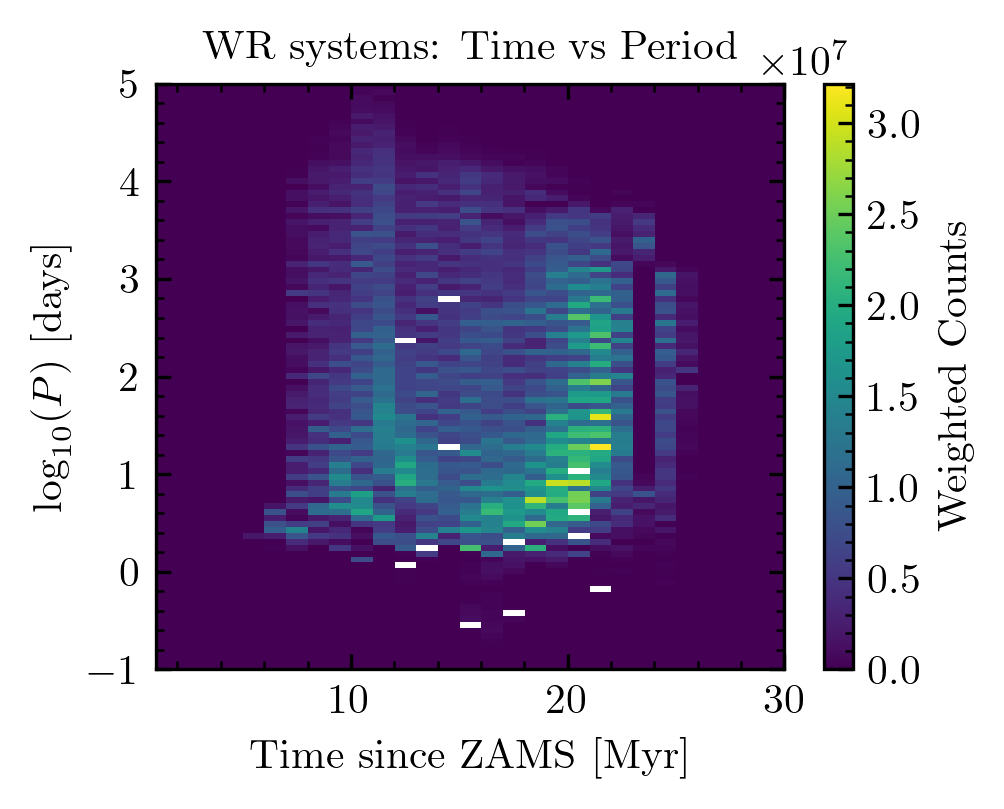

In [89]:
P_bins = np.logspace(-1, 5, 100)  # days
time_bins = np.logspace(np.log10(1e6), np.log10(3e7), 30)

# period array
period_array = []
time_array = []
weight_array = []
for key in WR_data:
    data = WR_data[key]['data']
    weights = WR_data[key]['weights']
    
    period_array.extend(data['orbital_period'].values)
    time_array.extend(data['time'].values)
    weight_array.extend(weights.values)


hist_2d, _, _ = np.histogram2d(time_array, period_array, bins=[time_bins, P_bins], weights=weight_array)

Y,X = np.meshgrid(time_bins, P_bins)

fig, ax = plt.subplots()
im = ax.imshow(hist_2d.T, origin='lower', aspect='auto',
          extent=[time_bins[0]/1e6, time_bins[-1]/1e6, np.log10(P_bins[0]), np.log10(P_bins[-1])],
          cmap='viridis')

#im = ax.pcolormesh(X, Y, hist_2d, cmap='viridis')
ax.set_xlabel('Time since ZAMS [Myr]')
ax.set_ylabel('$\log_{10}(P)$ [days]')
ax.set_title('WR systems: Time vs Period')
fig.colorbar(im, ax=ax, label='Weighted Counts')
plt.show()

(5.5, 3.6)

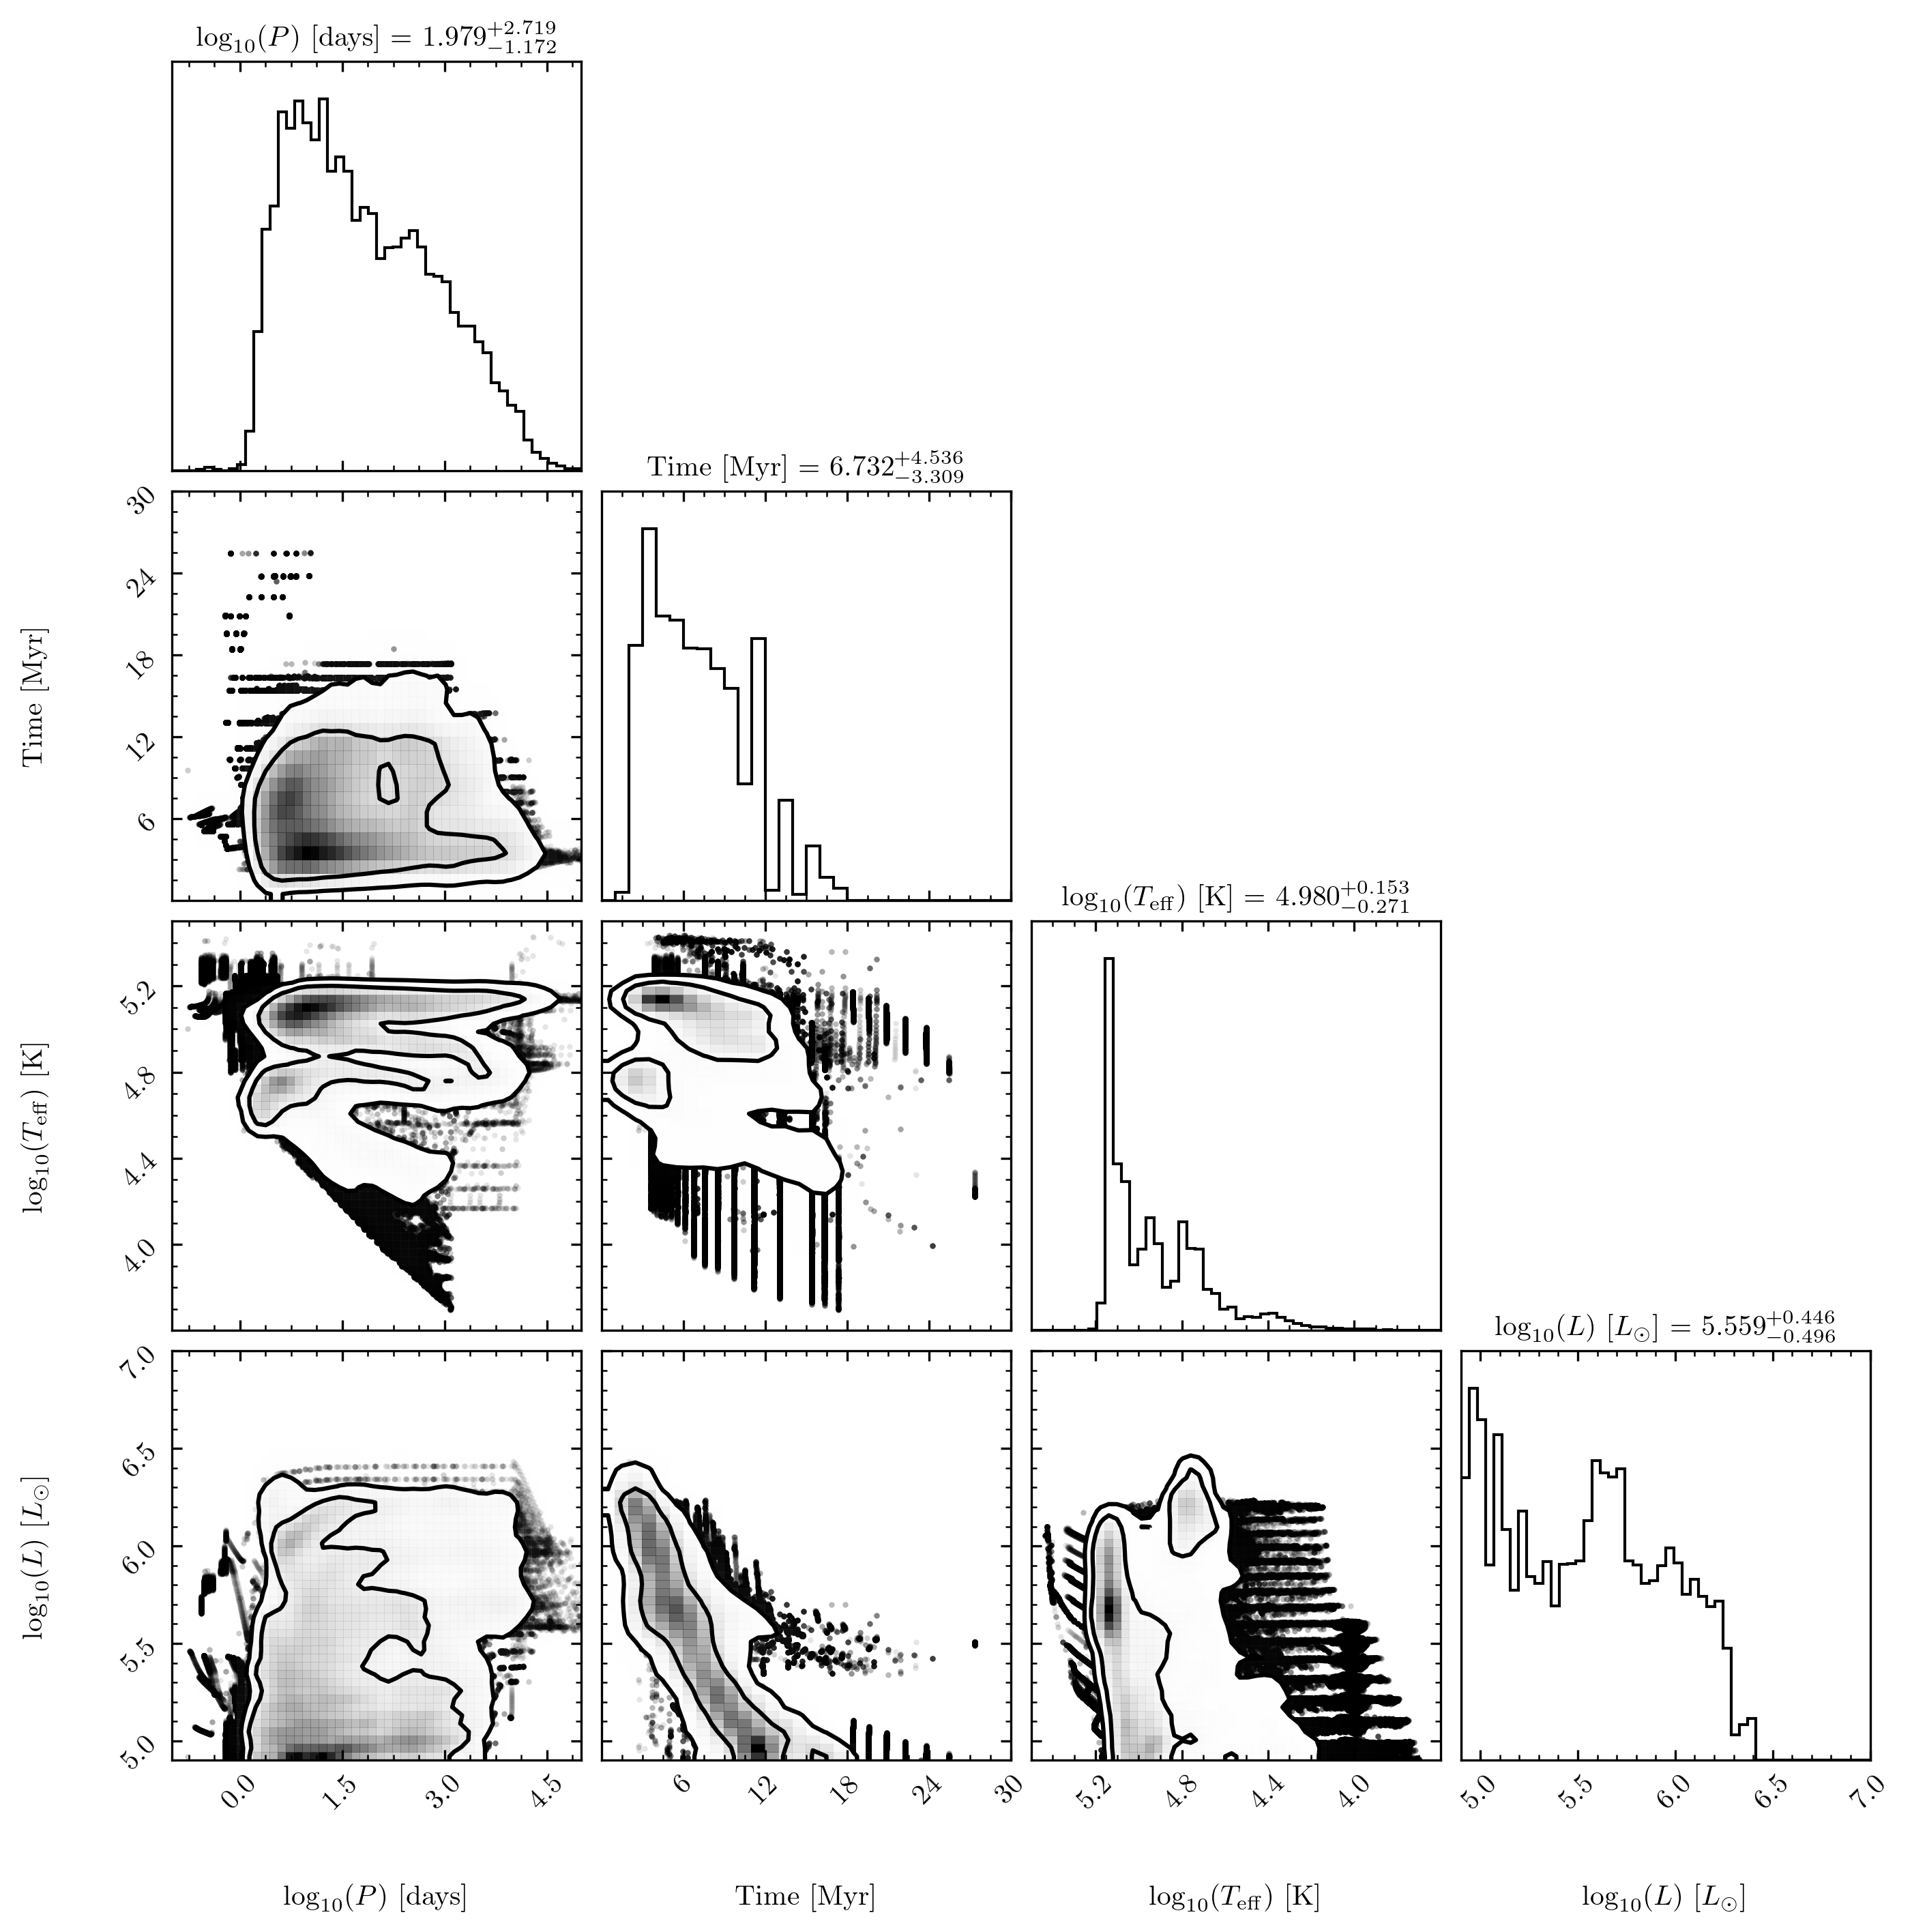

In [128]:
import corner

# Prepare data arrays for corner plot
period_array = []
time_array = []
teff_array = []
L_array = []
weight_array = []

for key in WR_data:
    data = WR_data[key]['data']
    weights = WR_data[key]['weights']
    
    # Get period and time
    period_array.extend(data['orbital_period'].values)
    time_array.extend(data['time'].values)
    
    # Calculate Teff
    L_vals = 10**data['S1_log_L'].values * 3.828e26  # L_sun to Watts
    R_vals = 10**data['S1_log_R'].values * 6.957e8   # R_sun to meters
    sigma = 5.67037442e-8
    Teff_vals = (L_vals / (4 * np.pi * R_vals**2 * sigma))**0.25
    teff_array.extend(np.log10(Teff_vals))
    
    # Get luminosity
    L_array.extend(data['S1_log_L'].values)
    
    # Get weights
    weight_array.extend(weights.values)


ranges = [
    (-1, 5),    # log10(P) in days
    (0, 30),    # Time in Myr
    (3.6, 5.5),     # log10(Teff) in K
    (4.9, 7)   # log10(L) in L_sun
]


# # Stack into array for corner plot
# # Using log10 of period and time/1e6 for better visualization
data_array = np.column_stack([
    np.log10(period_array),           # log10(P) in days
    np.array(time_array) / 1e6,       # Time in Myr
    teff_array,                        # log10(Teff) in K
    L_array                            # log10(L) in L_sun
])

valid_mask = (
    np.isfinite(data_array).all(axis=1) & 
    np.isfinite(weight_array) & 
    (np.array(weight_array) > 0)
)

data_array_clean = data_array[valid_mask]
weight_array_clean = np.array(weight_array)[valid_mask]

labels = [
    r'$\log_{10}(P)$ [days]',
    r'Time [Myr]',
    r'$\log_{10}(T_{\rm eff})$ [K]',
    r'$\log_{10}(L)$ [$L_\odot$]'
]

# # Create corner plot
fig = corner.corner(
    data_array_clean,
    labels=labels,
    weights=weight_array_clean,
    range=ranges,
    bins=[50, 30, 50, 50],
    smooth=1,
    show_titles=True,
    title_fmt='.3f',
    #quantiles=[0.16, 0.5, 0.84],
    levels=(0.68, 0.95),
    plot_datapoints=True,
    fill_contours=False,
    color='black'
)

# Extract the axes
axes = np.array(fig.axes).reshape((4, 4))

# Invert the x-axis of the Teff plots
axes[2,2].set_xlim(5.5, 3.6)
axes[3,2].set_xlim(5.5, 3.6)

# plt.suptitle('WR Population Corner Plot', y=1.02, fontsize=14)
# plt.show()

In [9]:
WR_data = {}

for i in range(100000):
    example = tmp_hist.loc[i]
    surface_threshold = 0.4
    luminosity_threshold = 4.9
    
    mask = example['S1_surface_h1'] < surface_threshold
    mask2 = example['event'] != 'CC1'
    stripped_phase = example[mask & mask2]
    
    # Check if stripped_phase is empty
    if len(stripped_phase) == 0:
        continue
    
    mask_L = stripped_phase['S1_log_L'] > luminosity_threshold
    stripped_phase = stripped_phase[mask_L]
    
    # Check again if stripped_phase is empty after applying luminosity threshold
    if len(stripped_phase) == 0:
        continue
        
    duration = stripped_phase['time'].iloc[-1] - stripped_phase['time'].iloc[0]
    start_time = stripped_phase['time'].iloc[0]
    end_time = stripped_phase['time'].iloc[-1]

    #stripped_phase
    WR_data[i] = {'duration': duration,
                  'data': stripped_phase}

In [10]:
from posydon.popsyn.synthetic_population import TransientPopulation
WR_pop = TransientPopulation(metallicity_file, transient_name='WR')
weights = WR_pop.model_weights('standard')

Missing ini parameter: metallicity


In [ ]:
WR_pop

In [15]:
def bin_wr_time_period_2d(WR_data, time_bins, period_bins, weights=None):
    """
    Create a 2D histogram of WR systems: time vs orbital period.
    
    For each time bin that overlaps with a WR phase:
    - Calculate the overlap fraction
    - Distribute that fraction across period bins based on time spent at each period
    
    Parameters:
    -----------
    WR_data : dict
        Dictionary with keys as system IDs, values containing 'data' DataFrame
    time_bins : array-like
        Bin edges for time axis (e.g., np.linspace(1e3, 3e7, 100))
    period_bins : array-like
        Bin edges for period axis (e.g., np.linspace(0.01, 6000, 100))
    weights : pd.Series or None
        Model weights for each system. If None, uses 1.0 for all.
    
    Returns:
    --------
    hist_2d : np.array
        2D histogram, shape (len(period_bins)-1, len(time_bins)-1)
    time_centers : np.array
    period_centers : np.array
    """
    n_time_bins = len(time_bins) - 1
    n_period_bins = len(period_bins) - 1
    hist_2d = np.zeros((n_period_bins, n_time_bins))
    
    for sys_id, wr_info in WR_data.items():
        data = wr_info['data']
        
        # Skip merged systems if desired
        if data['state'].iloc[0] == 'merged':
            continue
        
        # Get system weight
        sys_weight = weights.loc[sys_id] if weights is not None else 1.0
        
        times = data['time'].values
        periods = data['orbital_period'].values
        
        start_time = times[0]
        end_time = times[-1]
        total_duration = end_time - start_time
        
        if total_duration == 0:
            continue
        
        # For each time bin, check overlap
        for i_time in range(n_time_bins):
            t_bin_start = time_bins[i_time]
            t_bin_end = time_bins[i_time + 1]
            
            # Calculate overlap between WR phase and this time bin
            overlap_start = max(start_time, t_bin_start)
            overlap_end = min(end_time, t_bin_end)
            
            if overlap_start >= overlap_end:
                continue  # No overlap
            
            # Find data points within this time bin overlap
            mask = (times >= overlap_start) & (times <= overlap_end)
            
            if not np.any(mask):
                continue
            
            times_in_bin = times[mask]
            periods_in_bin = periods[mask]
            
            # Calculate time spent at each data point
            # Assign duration to each point based on time to neighbors
            if len(times_in_bin) == 1:
                # Single point - assign full overlap duration
                point_durations = np.array([overlap_end - overlap_start])
            else:
                point_durations = np.zeros(len(times_in_bin))
                
                for j in range(len(times_in_bin)):
                    if j == 0:
                        # First point: time from overlap_start to midpoint to next
                        t_start = overlap_start
                        t_end = (times_in_bin[j] + times_in_bin[j+1]) / 2
                    elif j == len(times_in_bin) - 1:
                        # Last point: time from midpoint from previous to overlap_end
                        t_start = (times_in_bin[j-1] + times_in_bin[j]) / 2
                        t_end = overlap_end
                    else:
                        # Middle point: midpoint before to midpoint after
                        t_start = (times_in_bin[j-1] + times_in_bin[j]) / 2
                        t_end = (times_in_bin[j] + times_in_bin[j+1]) / 2
                    
                    point_durations[j] = t_end - t_start
            
            # Now bin by period, weighted by duration at each period
            for period, duration in zip(periods_in_bin, point_durations):
                # Find which period bin this belongs to
                i_period = np.searchsorted(period_bins[1:], period)
                
                if 0 <= i_period < n_period_bins:
                    hist_2d[i_period, i_time] += sys_weight * duration
    
    # Calculate bin centers
    time_centers = (time_bins[:-1] + time_bins[1:]) / 2
    period_centers = (period_bins[:-1] + period_bins[1:]) / 2
    
    return hist_2d, time_centers, period_centers

/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_47442/3121123575.py:102: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


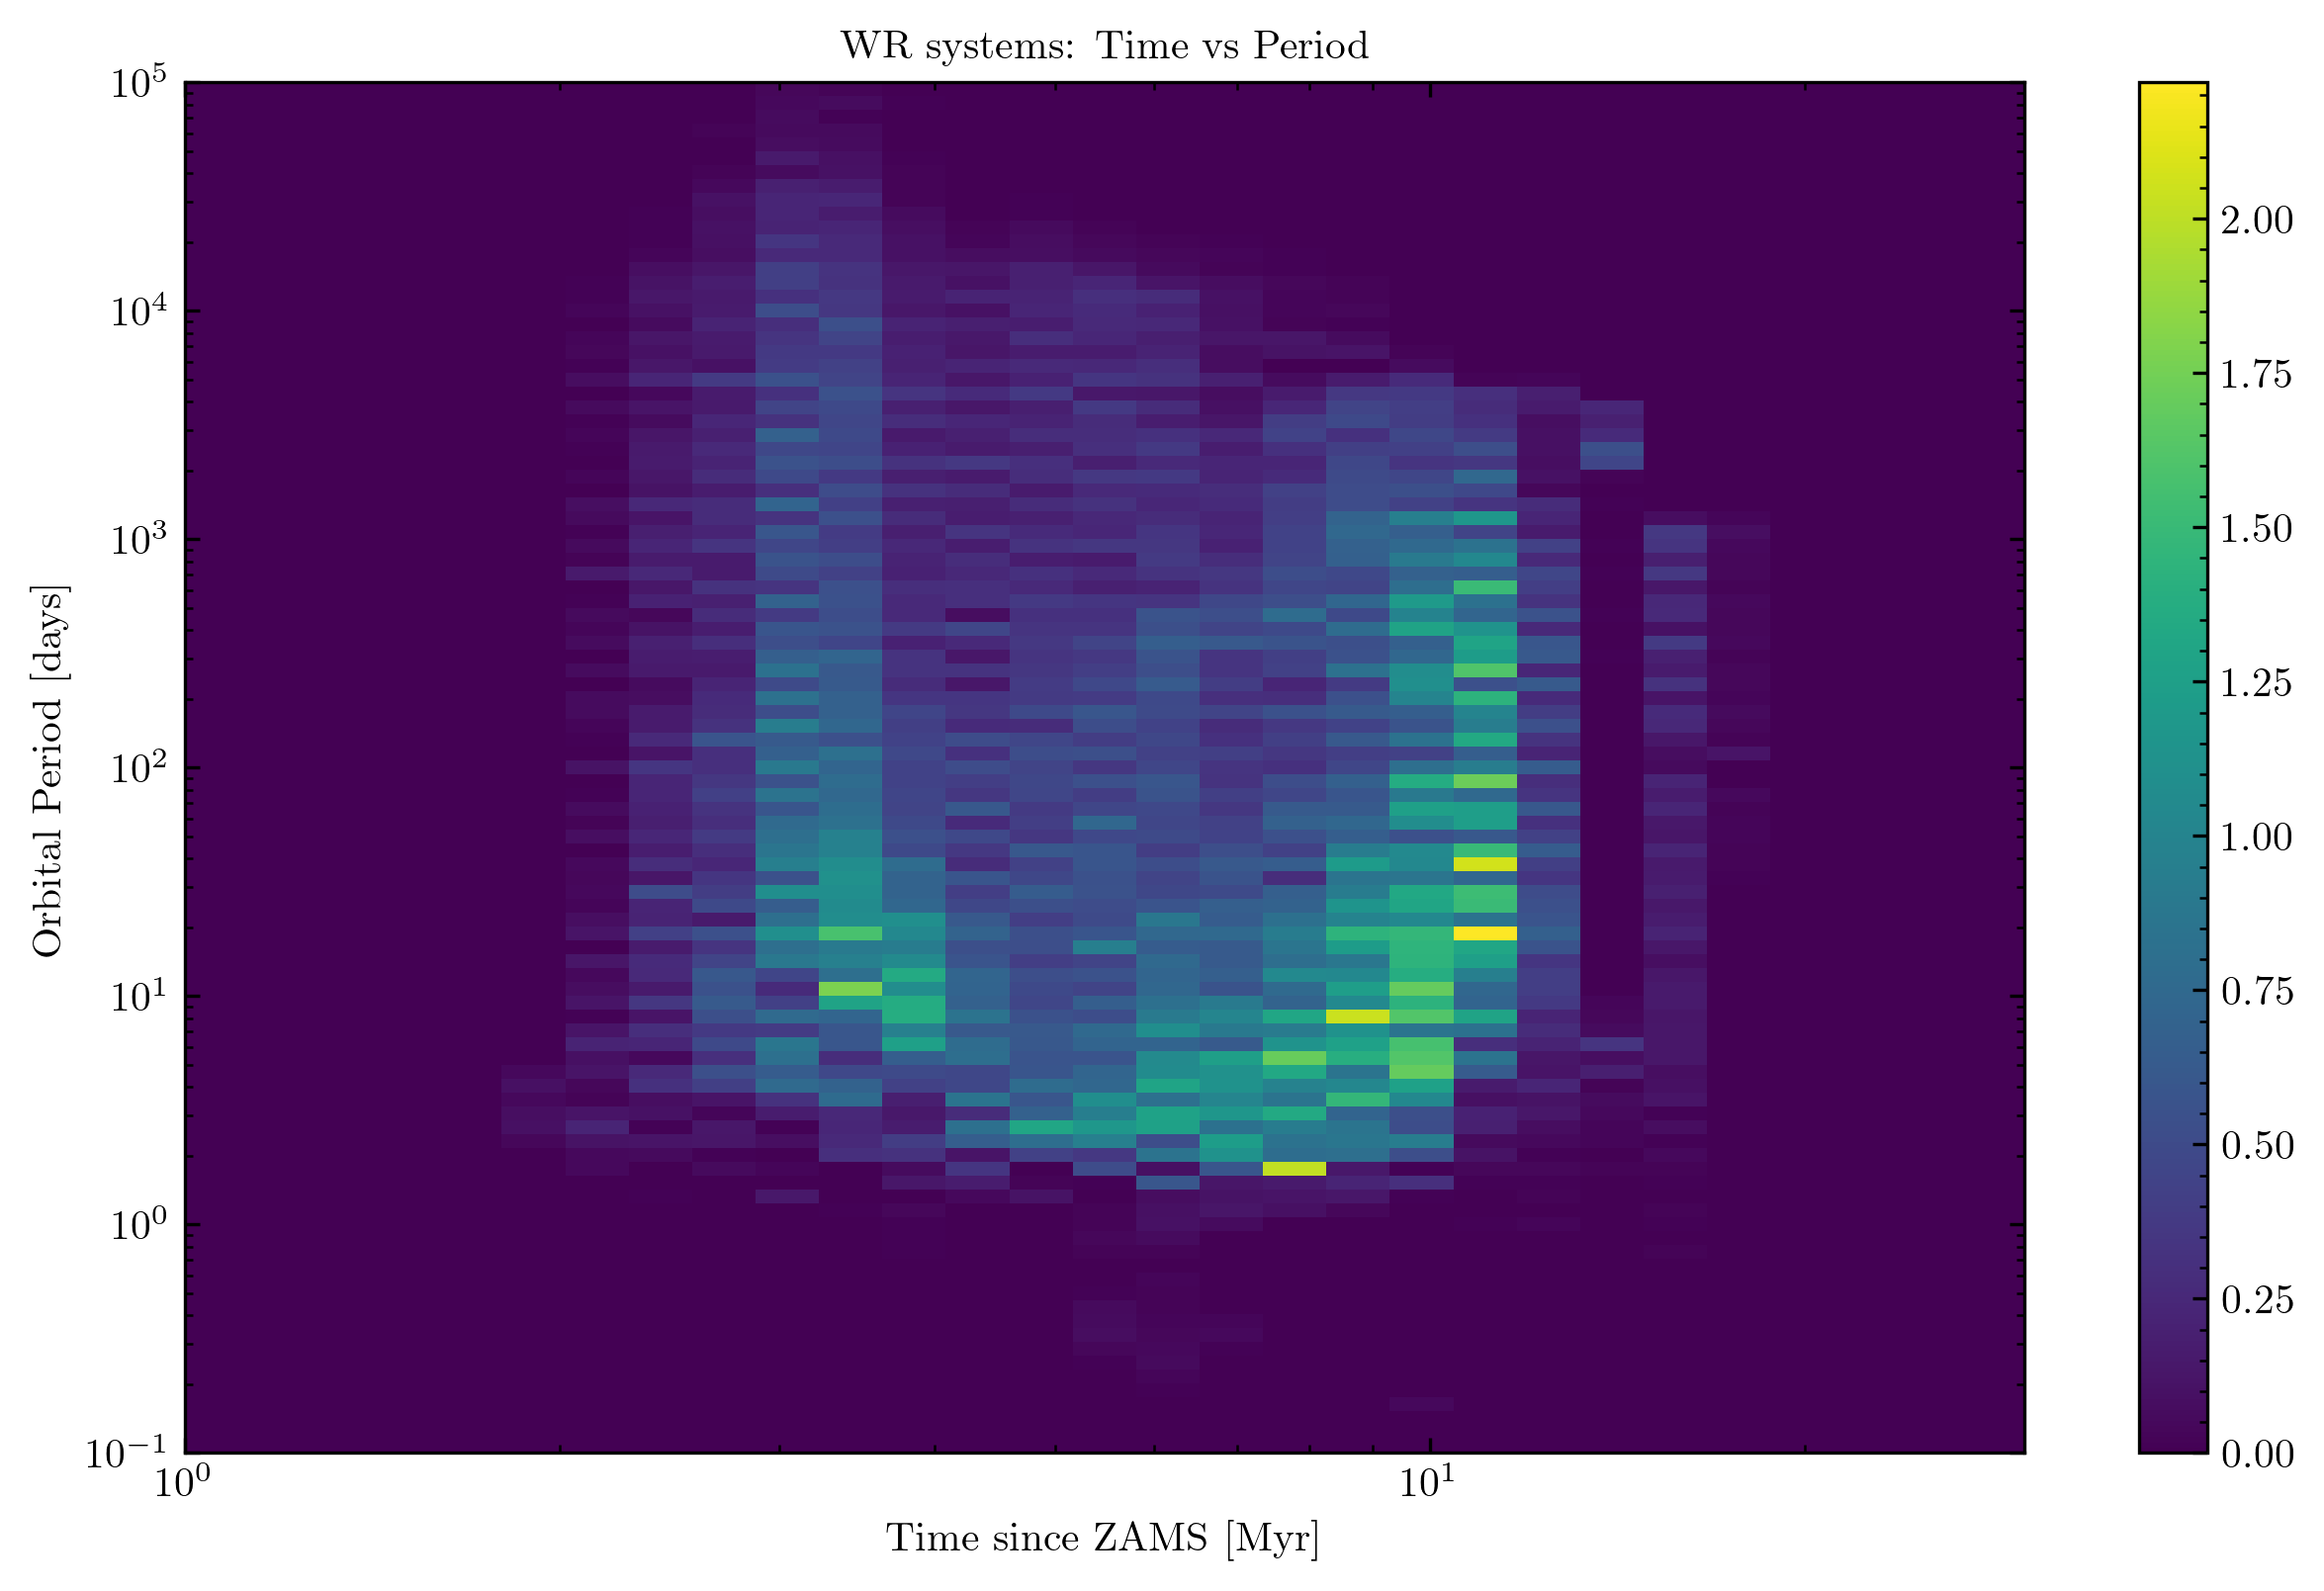

In [78]:
P_bins = np.logspace(-1, 5, 100)  # days
time_bins = np.logspace(np.log10(1e6), np.log10(3e7), 30)

hist_2d, time_centers, period_centers = bin_wr_time_period_2d(
    WR_data, 
    time_bins, 
    P_bins, 
    weights=weights
)

# Visualize
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.pcolormesh(time_bins/1e6, P_bins, hist_2d, shading='auto', cmap='viridis')
ax.set_xlabel('Time since ZAMS [Myr]')
ax.set_ylabel('Orbital Period [days]')
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title('WR systems: Time vs Period')
plt.colorbar(im, ax=ax,)
plt.show()

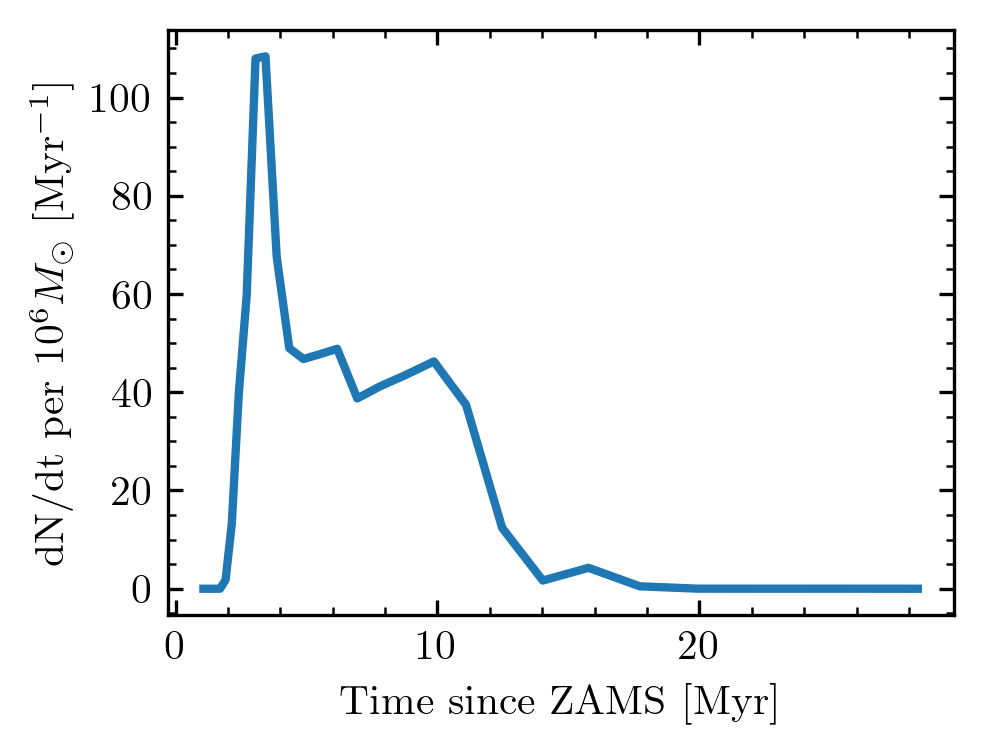

In [ ]:
# Sum over period axis to get WR count vs time
wr_count_vs_time = np.sum(hist_2d, axis=0) * 1e6
time_bin_widths = np.diff(time_bins)

# Plot
fig, ax = plt.subplots()
ax.plot(time_centers/1e6, wr_count_vs_time/time_bin_widths, lw=2)
ax.set_xlabel('Time since ZAMS [Myr]')
ax.set_ylabel('dN/dt per $10^6 M_\odot$ [Myr$^{-1}$]')
plt.show()

In [1]:
# Sum over period axis to get WR count vs time
wr_count_vs_time = np.sum(hist_2d, axis=1)
bin_widths = np.diff(P_bins)


# Plot
fig, ax = plt.subplots()
ax.plot(period_centers, wr_count_vs_time/bin_widths, lw=2)
ax.set_xlabel('Orbital Period [days]')
ax.set_ylabel('dN/dP for $1M_\odot$/yr ')
plt.xscale('log')
plt.show()

NameError: name 'np' is not defined

In [79]:
import pickle
WR_data = pickle.load(open(f'WR_data_{met_str}_Zsun.pkl', 'rb'))

In [6]:
def WR_pop_sel(history_chunk, oneline_chunk, formation_channels_chunk=None):
    global WR_data
    WR_indices = WR_data.keys()

    selected_idx = oneline_chunk.index.isin(WR_indices)
    idx_selected = oneline_chunk.index[selected_idx].to_list()
    if len(idx_selected) == 0:
        return pd.DataFrame()
    df = pd.DataFrame(index=idx_selected)
    time_list = []
    duration_list = []
    metallicity_list = []
    
    for i in idx_selected:
        time_list.append(WR_data[i]['data']['time'].iloc[0])
        duration_list.append(WR_data[i]['duration'])
        metallicity_list.append(oneline_chunk.loc[i,'metallicity'])
        
    df['time'] = time_list
    df['WR_duration'] = duration_list
    df['metallicity'] = metallicity_list
        
    return df

In [ ]:
# testing
WR_pop_sel(pop.oneline[0:50], pop.oneline[0:50])

,time,WR_duration,metallicity
8,1.736027e+07,38098.312940,1.0
15,1.180968e+07,26105.316325,1.0
22,5.134268e+06,376398.596483,1.0
24,4.710893e+06,321432.261725,1.0
25,9.107709e+06,314808.639705,1.0
27,5.120277e+06,244730.264754,1.0
28,1.541980e+07,30084.818118,1.0
34,7.903527e+06,203357.531154,1.0
36,1.120169e+07,614247.292520,1.0
37,1.735795e+07,4057.212747,1.0


In [ ]:
WR_pop = pop.create_transient_population(WR_pop_sel, 'WR')

overwriting transient population
Missing ini parameter: metallicity


In [100]:
from posydon.popsyn.synthetic_population import TransientPopulation
WR_pop = TransientPopulation(metallicity_file, transient_name='WR')

Missing ini parameter: metallicity


In [ ]:
population_params = {
    'binary_fraction_scheme':'const',
    'binary_fraction_const': 1.0,
    
    # extending the IMF to higher and lower masses
    'primary_mass_scheme':'Kroupa2001',
    'primary_mass_min': 0.01,
    'primary_mass_max': 300,
    
    # overwriting q_min and q_max for flat mass ratio    
    'secondary_mass_scheme': 'flat_mass_ratio',
    'secondary_mass_min': 0.01,
    'secondary_mass_max': 300,
    'q_min': 0,
    'q_max': 1,
    
    # orbital parameters
    'orbital_scheme':'period',
    'orbital_period_scheme':'Sana+12_period_extended',
    'orbital_period_min':0.75,
    'orbital_period_max':6000,
}

In [ ]:
# calculate model weights for each WR
weights = WR_pop.calculate_model_weights(model_weights_identifier='standard', population_parameters=population_params)

In [81]:
def bin_wr_durations(WR_data, time_bins, weights=None):
    # Initialize weights array
    n_bins = len(time_bins) - 1
    bin_weights = np.zeros(n_bins)
    
    # Default weights to 1.0 if not provided
    if weights is None:
        weights = {key: 1.0 for key in WR_data.keys()}
    
    # Process each WR system
    for sys_id, wr_info in WR_data.items():
        # Get start and end times
        start_time = wr_info['data']['time'].iloc[0]
        end_time = wr_info['data']['time'].iloc[-1]
        total_duration = end_time - start_time
        
        # Get weight for this system
        sys_weight = weights.loc[sys_id]
        
        # Skip if duration is zero
        if total_duration == 0:
            continue
        
        # Find which bins this WR phase overlaps with
        for i in range(n_bins):
            bin_start = time_bins[i]
            bin_end = time_bins[i + 1]
            bin_width = bin_end - bin_start
            
            # Calculate overlap between WR phase and this bin
            overlap_start = max(start_time, bin_start)
            overlap_end = min(end_time, bin_end)
            
            # If there's overlap, add proportional weight
            if overlap_start < overlap_end:
                overlap_duration = overlap_end - overlap_start
                fraction = overlap_duration / bin_width
                bin_weights[i] += sys_weight * fraction
                
    
    # Calculate bin centers (geometric mean for log-spaced bins)
    bin_centers = np.sqrt(time_bins[:-1] * time_bins[1:])
    
    return bin_weights, bin_centers

/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


(0.0, 53.676693468059746)

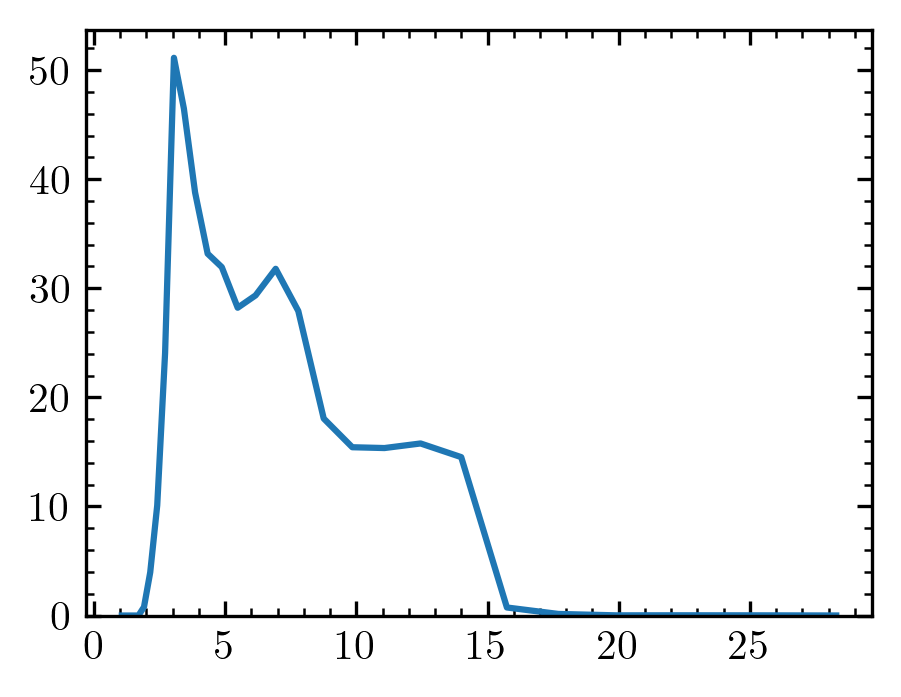

In [82]:
time_bins = np.logspace(np.log10(1e6), np.log10(3e7), 30)
weights = WR_pop.model_weights('standard')
bin_weights, bin_centers = bin_wr_durations(WR_data, time_bins, weights=weights)

plt.plot(bin_centers/1e6, bin_weights*1e6)
plt.ylim(0)

## primaries that have merged

These are observed as single WRs.

/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


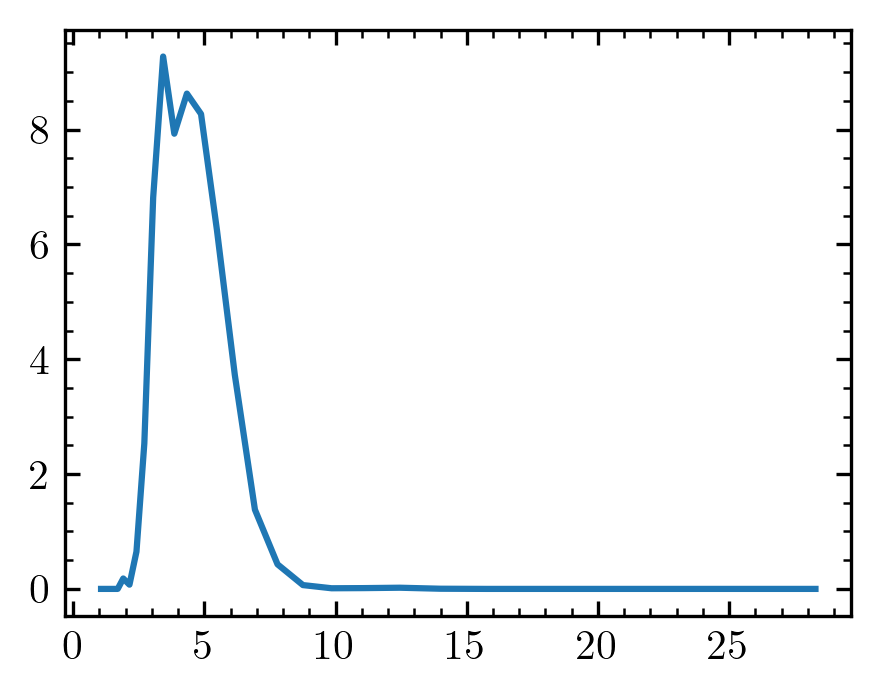

In [83]:
merged_WR_data = {}
for key, value in WR_data.items():
    state = WR_data[key]['data']['state']
    mask = state == 'merged'
    if np.any(mask):
        merged_WR_data[key] = value

merged_bin_weights, merged_bin_centers = bin_wr_durations(merged_WR_data, time_bins, weights=weights)
plt.plot(merged_bin_centers/1e6, merged_bin_weights*1e6)

/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


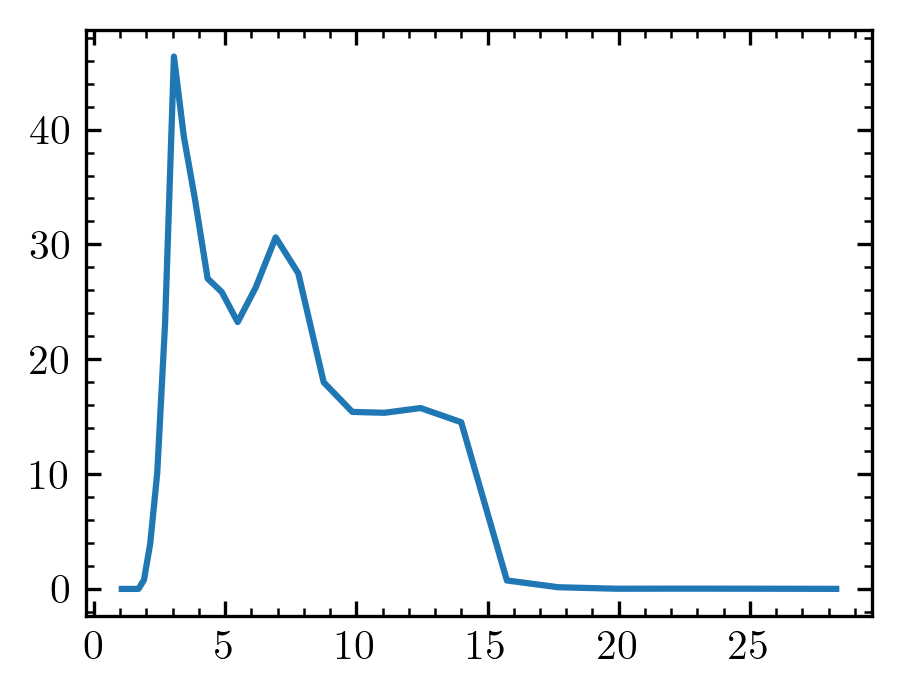

In [84]:
not_merged_WR_data = {}
for key, value in WR_data.items():
    state = WR_data[key]['data']['state']
    mask = state == 'merged'
    if np.any(~mask):
        not_merged_WR_data[key] = value

not_merged_bin_weights, not_merged_bin_centers = bin_wr_durations(not_merged_WR_data, time_bins, weights=weights)
plt.plot(not_merged_bin_centers/1e6, not_merged_bin_weights*1e6)

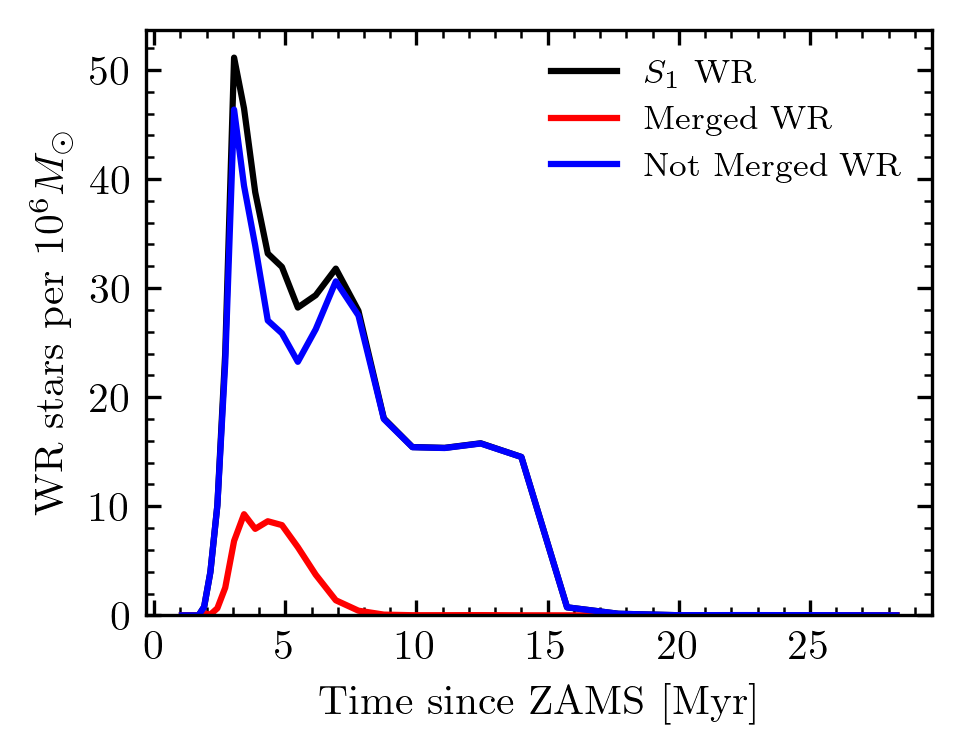

In [85]:
plt.plot(bin_centers/1e6, bin_weights*1e6, label='$S_1$ WR', color='black')
plt.plot(merged_bin_centers/1e6, merged_bin_weights*1e6, label='Merged WR', color='red')
plt.plot(not_merged_bin_centers/1e6, not_merged_bin_weights*1e6, label='Not Merged WR', color='blue')
plt.ylim(0)
plt.xlabel('Time since ZAMS [Myr]')
plt.ylabel('WR stars per $10^6 M_\odot$')
plt.legend()
plt.show()

In [86]:
# split per interaction type
# stable, unstable, no interaction, NaN (no interaction too)
oneline_data = WR_pop.oneline[list(WR_data.keys())]['interp_class_HMS_HMS']

In [87]:
# stable
stable_WR_data = {}
# stable indices
stable_indices = oneline_data[oneline_data == 'stable_MT'].index
for i in stable_indices:
    stable_WR_data[i] = WR_data[i]
    
unstable_indices = oneline_data[oneline_data == 'unstable_MT'].index
unstable_WR_data = {}
for i in unstable_indices:
    unstable_WR_data[i] = WR_data[i]
    
stable_reverse_indices = oneline_data[oneline_data == 'stable_reverse_MT'].index
stable_reverse_WR_data = {}
for i in stable_reverse_indices:
    stable_reverse_WR_data[i] = WR_data[i]

no_interaction_indices = oneline_data[pd.isna(oneline_data) | (oneline_data == 'no_MT')].index
no_interaction_WR_data = {}
for i in no_interaction_indices:
    no_interaction_WR_data[i] = WR_data[i]    

In [88]:
oneline_data.unique()

array(['stable_MT', 'unstable_MT', 'no_MT', nan, 'stable_reverse_MT'],
      dtype=object)

/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


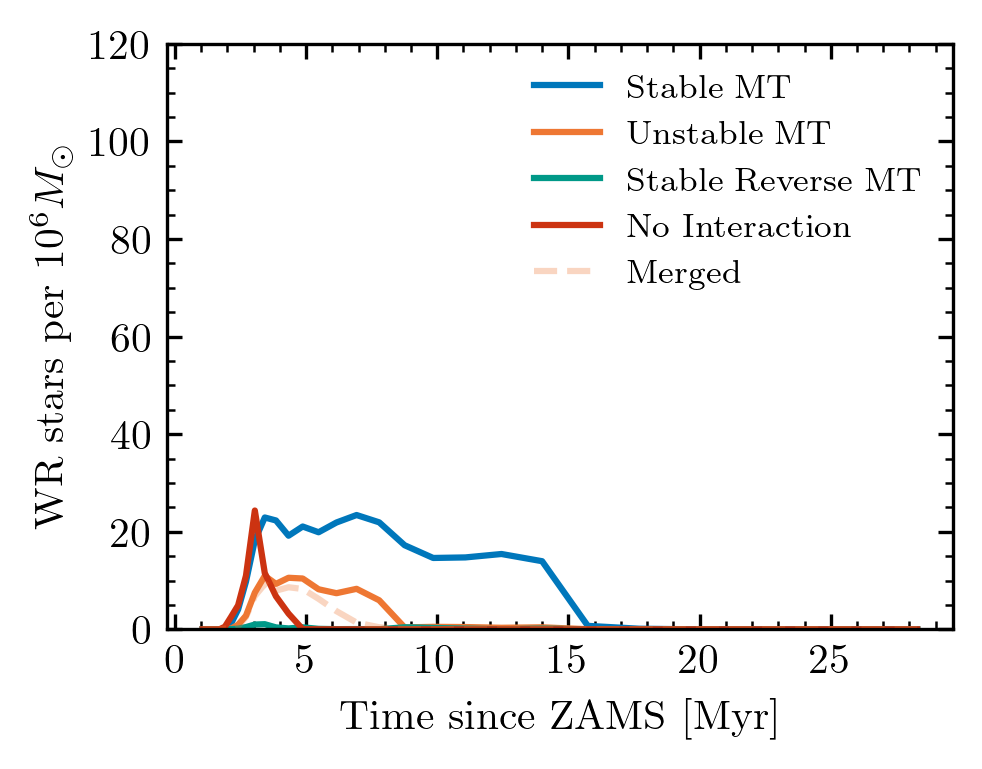

In [89]:

data_array =  [stable_WR_data, unstable_WR_data, stable_reverse_WR_data, no_interaction_WR_data]
label_array = ['Stable MT', 'Unstable MT', 'Stable Reverse MT', 'No Interaction']

colour_array = ['#0077BB', '#EE7733', '#009988', '#CC3311']
for data, label, colour in zip(data_array, label_array, colour_array):
    bin_weights, bin_centers = bin_wr_durations(data, time_bins, weights=weights)
    plt.plot(bin_centers/1e6, bin_weights*1e6, label=label, color=colour)


# merged 
plt.plot(merged_bin_centers/1e6, merged_bin_weights*1e6, color=colour_array[1], alpha=0.3, linestyle='--', label='Merged')

plt.ylim(0, 120)
plt.legend()
plt.xlabel('Time since ZAMS [Myr]')
plt.ylabel('WR stars per $10^6 M_\odot$')
plt.show()


## grid slice example

In [2]:
def plot_grid_slice_for_q(q, ax, grid, marker_colours):
    """
    Plot a grid slice for a specific mass ratio q value.
    
    Parameters
    -----------
    q : float
        Mass ratio (M2/M1) to plot
    ax : matplotlib.axes.Axes
        Axis to plot on
    grid : PSyGrid
        The stellar evolution grid
    marker_colours : dict
        Dictionary of colors for different markers
    """
    M1_unique = np.unique(grid.initial_values['star_1_mass'])
    
    # Select all binaries with the specified q value
    mask_out = np.isclose(M1_unique[0], grid.initial_values['star_1_mass'], atol=1e-2)
    mask_out = mask_out & np.isclose(grid.initial_values['star_2_mass'], M1_unique[0]*q, atol=1e-2)

    for M1 in M1_unique[1:]:
        mask = np.isclose(M1, grid.initial_values['star_1_mass'], atol=1e-2)
        mask = mask & (np.isclose(grid.initial_values['star_2_mass'], M1*q, atol=1e-2))
        mask_out = mask_out | mask
        
    s_marker = 5

    # Plot no MT cases
    no_MT_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'no_MT')
    if np.any(no_MT_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][no_MT_mask],
                grid.initial_values['period_days'][mask_out][no_MT_mask],
                s=s_marker,
                marker='s',
                facecolor=marker_colours['no_MT'])
        
    # Plot not converged or initial mass transfer
    not_converged_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'not_converged') | \
                         np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'initial_MT')
    if np.any(not_converged_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][not_converged_mask],
                    grid.initial_values['period_days'][mask_out][not_converged_mask],
                    s=2,
                    marker='.',
                    color=marker_colours['not_converged'],
                    linewidth=0.4, label='initial MT or not converged')
    
    # Plot unstable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'unstable_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                    grid.initial_values['period_days'][mask_out][mask_IC],
                    s=s_marker-3,
                    marker='D',
                    color=marker_colours['unstable'],
                    label='unstable MT')
    
    # Plot stable MT cases
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                grid.initial_values['period_days'][mask_out][mask_IC],
                s=s_marker-2,
                marker='s',
                color=marker_colours['stable'],
                label='stable MT')
            
    # Plot reverse stable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_reverse_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                grid.initial_values['period_days'][mask_out][mask_IC],
                s=s_marker-2,
                marker='o',
                color=marker_colours['reverse_stable_MT'],
                label='reverse stable MT')
            
    # Set plot properties
    ax.set_xscale('log')
    ax.set_yscale('log')
    
    return ax


def plot_data_points(ax, oneline_sel, q, metallicity, colour):
    
    # Plot BBH mergers as contours
    Z_mask = np.isclose(oneline_sel['metallicity'], metallicity, atol=1e-7)
    q_mask = np.isclose(oneline_sel['S2_mass_i']/oneline_sel['S1_mass_i'], q, atol=1e-2)
    
    ax.scatter(oneline_sel['S1_mass_i'][Z_mask & q_mask],
                oneline_sel['orbital_period_i'][Z_mask & q_mask],
                s=1,
                color=colour,
                marker='^',
                alpha=1,
                zorder=10)
    
    return ax

In [3]:
from posydon.config import PATH_TO_POSYDON_DATA
from posydon.grids.psygrid import PSyGrid
def load_grid_data(metallicity):
    """
    Load the HMS-HMS grid data.
    
    Parameters
    ----------
    metallicity : float
        Metallicity value.
        
    Returns
    -------
    PSyGrid
        Grid object containing stellar evolution data
    """
    print("  Loading HMS-HMS grid...")
    str_met = convert_metallicity_to_string(metallicity)
    HMS_HMS_file = Path(PATH_TO_POSYDON_DATA) / 'HMS-HMS' / f'{str_met}_Zsun.h5'
    grid = PSyGrid(str(HMS_HMS_file))
    print(f"    ✓ Loaded grid")
    
    return grid

In [ ]:

marker_colours = {
    'stable': "#0077BB",
    "unstable": "#CC3311",
    "no_MT": '#BBBBBB',
    "not_converged": "black",
    "reverse_stable_MT":'#009988',
}

q=0.4
fig, ax = plt.subplots()

grid = load_grid_data(metallicity)
ax = plot_grid_slice_for_q(q, ax, grid, marker_colours)


oneline_sel = WR_pop.oneline[list(WR_data.keys())]
#ax = plot_data_points(ax, oneline_sel, q, metallicity, colour='black')

ax = plot_data_points(ax, oneline_sel.loc[stable_indices], q, metallicity, colour='black')
ax = plot_data_points(ax, oneline_sel.loc[unstable_indices], q, metallicity, colour='black')
ax = plot_data_points(ax, oneline_sel.loc[stable_reverse_indices], q, metallicity, colour='black')
ax = plot_data_points(ax, oneline_sel.loc[no_interaction_indices], q, metallicity, colour='black')

ax = plot_data_points(ax, oneline_sel.loc[merged_WR_data.keys()], q, metallicity, colour='orange')

ax.set_title(f'$q = {q:.2f}$')
ax.set_xlabel('$M_\mathrm{1, ZAMS}$ [$M_\odot$]')

NameError: name 'plt' is not defined

# Across metallicity:



In [75]:
def WR_pop_sel(history_chunk, oneline_chunk, formation_channels_chunk=None):
    global WR_data
    WR_indices = WR_data.keys()

    selected_idx = oneline_chunk.index.isin(WR_indices)
    idx_selected = oneline_chunk.index[selected_idx].to_list()
    if len(idx_selected) == 0:
        return pd.DataFrame()
    df = pd.DataFrame(index=idx_selected)
    time_list = []
    duration_list = []
    metallicity_list = []
    
    for i in idx_selected:
        time_list.append(WR_data[i]['data']['time'].iloc[0])
        duration_list.append(WR_data[i]['duration'])
        metallicity_list.append(oneline_chunk.loc[i,'metallicity'])
        
    df['time'] = time_list
    df['WR_duration'] = duration_list
    df['metallicity'] = metallicity_list
        
    return df

population_params = {
    'binary_fraction_scheme':'const',
    'binary_fraction_const': 1.0,
    
    # extending the IMF to higher and lower masses
    'primary_mass_scheme':'Kroupa2001',
    'primary_mass_min': 0.01,
    'primary_mass_max': 300,
    
    # overwriting q_min and q_max for flat mass ratio    
    'secondary_mass_scheme': 'flat_mass_ratio',
    'secondary_mass_min': 0.01,
    'secondary_mass_max': 300,
    'q_min': 0,
    'q_max': 1,
    
    # orbital parameters
    'orbital_scheme':'period',
    'orbital_period_scheme':'Sana+12_period_extended',
    'orbital_period_min':0.75,
    'orbital_period_max':6000,
}

In [92]:
from posydon.utils.common_functions import convert_metallicity_to_string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from posydon.config import PATH_TO_POSYDON

plt.style.use(str(Path(PATH_TO_POSYDON) / 'posydon' / 'visualization' / 'posydon.mplstyle'))

data_folder = '/Users/max/Documents/projects/WR_population/population_synthesis/runs/2025_11_04/'

for metallicity in [0.01, 0.1, 0.2, 0.45, 1.0]:
    print(metallicity)
    met_str = convert_metallicity_to_string(metallicity)
    metallicity_file = data_folder + f"{met_str}_Zsun_population.h5"
    pop = Population(metallicity_file)
    # S1 only
    tmp_hist = pop.history[['S1_surface_h1', 'time', 'state', 'event', 'step_names', 'S1_log_L', 'S1_mass', 'S2_mass', 'S1_state', 'S2_state', 'S2_log_L', 'S1_log_R', 'S2_log_R']]
    WR_data = {}
    for i in range(100000):
        example = tmp_hist.loc[i]
        surface_threshold = 0.4
        luminosity_threshold = 4.9 - np.log10(metallicity)
        
        mask = example['S1_surface_h1'] < surface_threshold
        mask2 = example['event'] != 'CC1'
        stripped_phase = example[mask & mask2]
        
        # Check if stripped_phase is empty
        if len(stripped_phase) == 0:
            continue
        
        mask_L = stripped_phase['S1_log_L'] > luminosity_threshold
        stripped_phase = stripped_phase[mask_L]
        
        # Check again if stripped_phase is empty after applying luminosity threshold
        if len(stripped_phase) == 0:
            continue
            
        duration = stripped_phase['time'].iloc[-1] - stripped_phase['time'].iloc[0]
        start_time = stripped_phase['time'].iloc[0]
        end_time = stripped_phase['time'].iloc[-1]

        #stripped_phase
        WR_data[i] = {'duration': duration,
                    'data': stripped_phase}
        
        # write WR_data to file
    import pickle
    with open(f'WR_data_{met_str}_Zsun_shiftL.pkl', 'wb') as f:
        pickle.dump(WR_data, f)
        
    # create weights
    WR_pop = pop.create_transient_population(WR_pop_sel, 'WR_shiftL')
    # calculate model weights for each WR
    weights = WR_pop.calculate_model_weights(model_weights_identifier='standard', population_parameters=population_params)

0.01
Missing ini parameter: metallicity
Missing ini parameter: metallicity
0.1
Missing ini parameter: metallicity
Missing ini parameter: metallicity
0.2
Missing ini parameter: metallicity
Missing ini parameter: metallicity
0.45
Missing ini parameter: metallicity
Missing ini parameter: metallicity
1.0
Missing ini parameter: metallicity
Missing ini parameter: metallicity


0.01
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


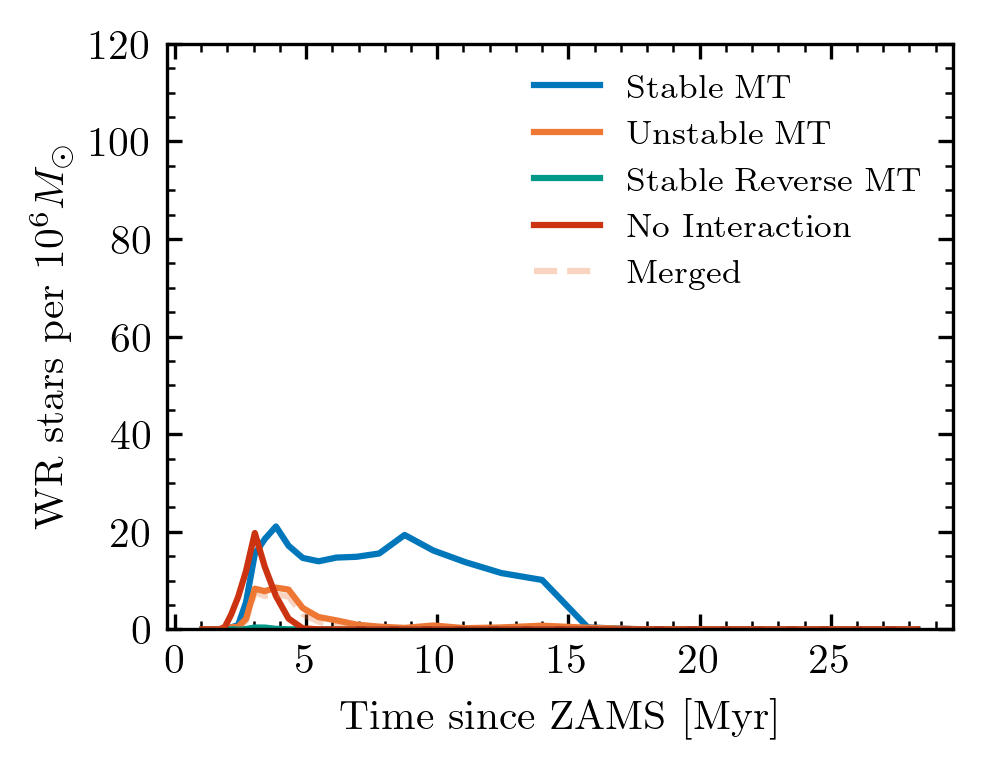

0.1
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


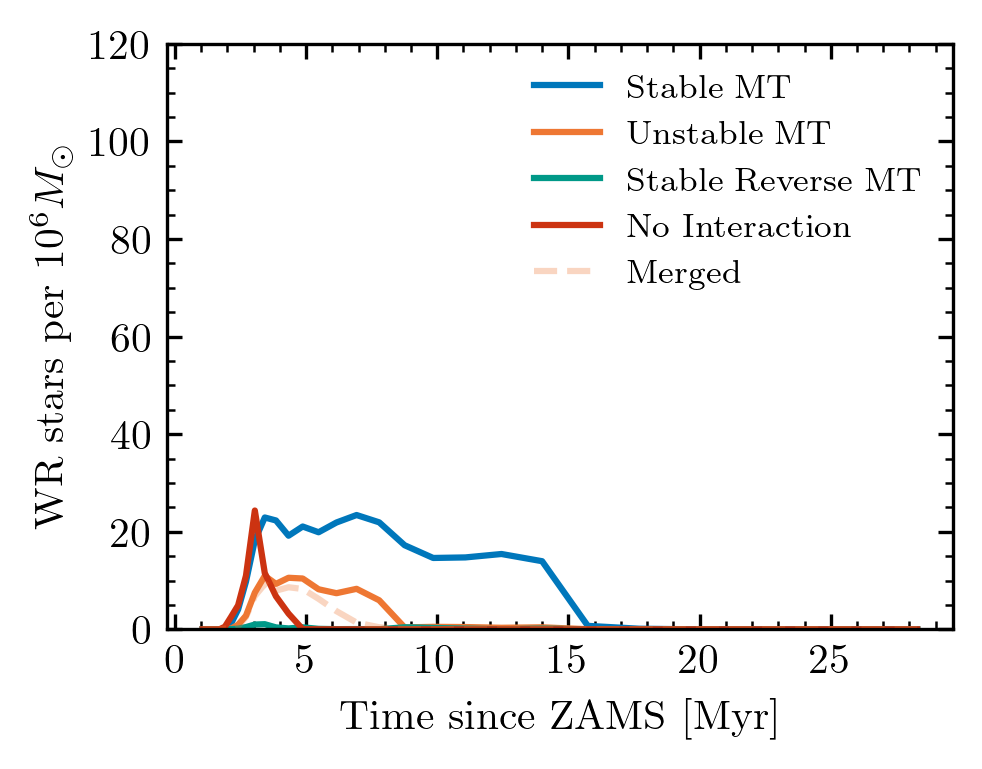

0.2
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


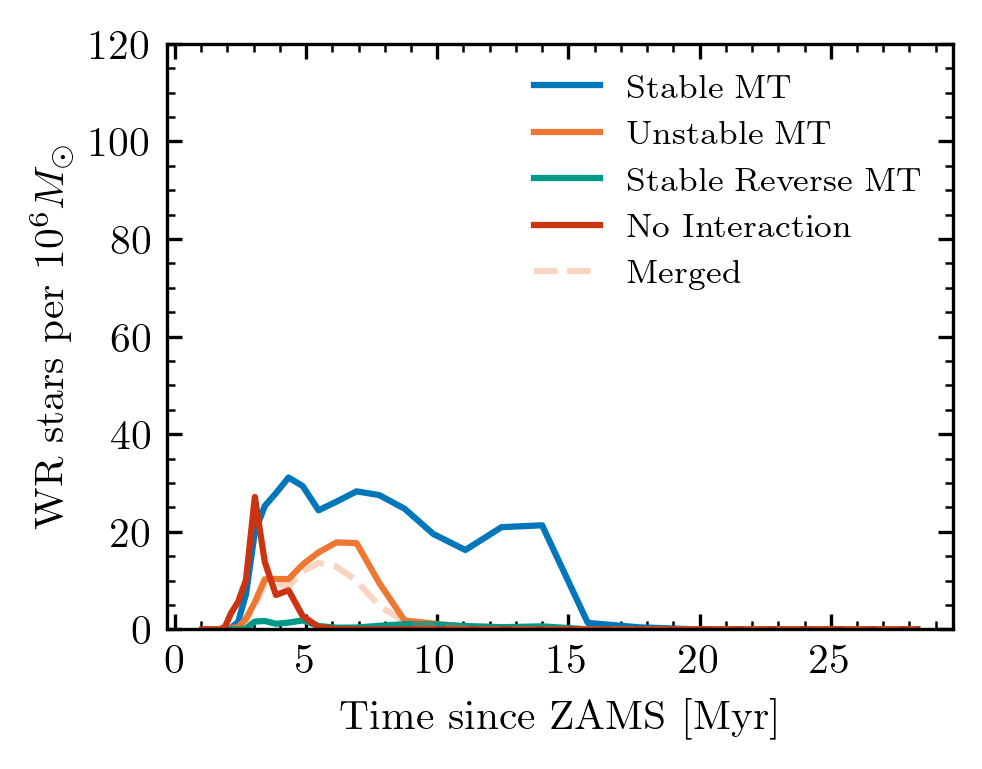

0.45
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


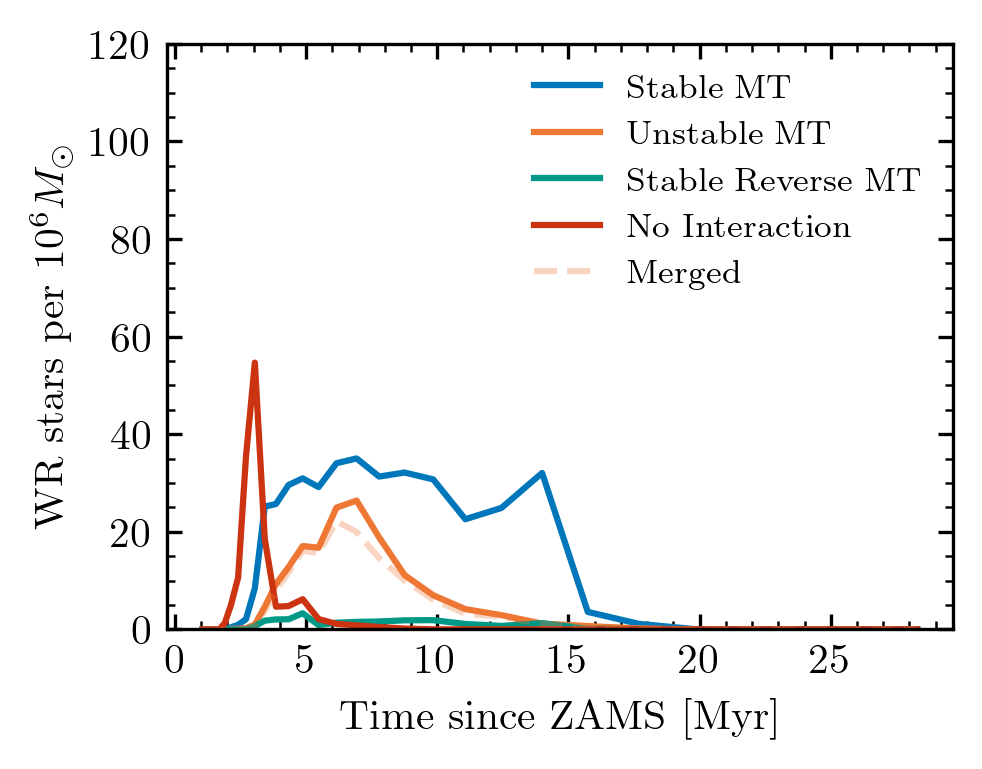

1.0
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


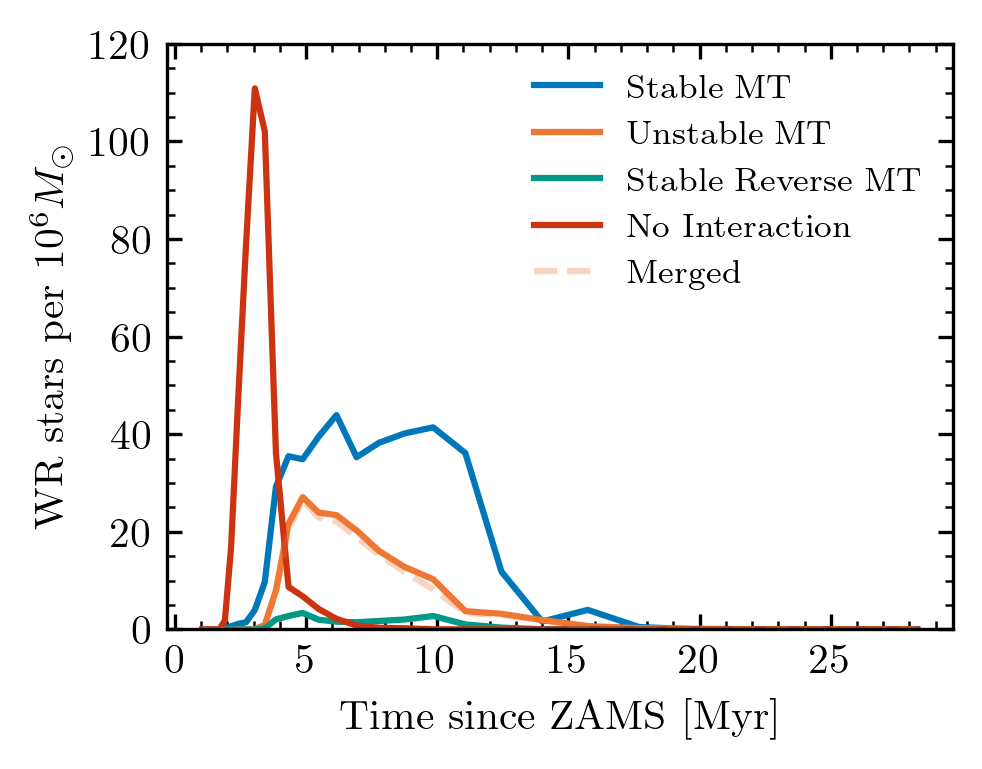

<Figure size 1014x760.5 with 0 Axes>

In [91]:
for metallicity in [0.01, 0.1, 0.2, 0.45, 1.0]:
    print(metallicity)
    met_str = convert_metallicity_to_string(metallicity)
    WR_data = pickle.load(open(f'WR_data_{met_str}_Zsun.pkl', 'rb'))
    pop = Population(data_folder + f"{met_str}_Zsun_population.h5")
    WR_pop = TransientPopulation(data_folder + f"{met_str}_Zsun_population.h5", transient_name='WR')
    weights = WR_pop.model_weights('standard')
    
    # shifting WR boundary in L
    
    # split per interaction type
    # stable, unstable, no interaction, NaN (no interaction too)
    oneline_data = WR_pop.oneline[list(WR_data.keys())]['interp_class_HMS_HMS']
    
    # stable
    stable_WR_data = {}
    # stable indices
    stable_indices = oneline_data[oneline_data == 'stable_MT'].index
    for i in stable_indices:
        stable_WR_data[i] = WR_data[i]
        
    unstable_indices = oneline_data[oneline_data == 'unstable_MT'].index
    unstable_WR_data = {}
    for i in unstable_indices:
        unstable_WR_data[i] = WR_data[i]
        
    stable_reverse_indices = oneline_data[oneline_data == 'stable_reverse_MT'].index
    stable_reverse_WR_data = {}
    for i in stable_reverse_indices:
        stable_reverse_WR_data[i] = WR_data[i]

    no_interaction_indices = oneline_data[pd.isna(oneline_data) | (oneline_data == 'no_MT')].index
    no_interaction_WR_data = {}
    for i in no_interaction_indices:
        no_interaction_WR_data[i] = WR_data[i]    
    
    data_array =  [stable_WR_data, unstable_WR_data, stable_reverse_WR_data, no_interaction_WR_data]
    label_array = ['Stable MT', 'Unstable MT', 'Stable Reverse MT', 'No Interaction']

    colour_array = ['#0077BB', '#EE7733', '#009988', '#CC3311']
    for data, label, colour in zip(data_array, label_array, colour_array):
        bin_weights, bin_centers = bin_wr_durations(data, time_bins, weights=weights)
        plt.plot(bin_centers/1e6, bin_weights*1e6, label=label, color=colour)

    # merged
    merged_WR_data = {}
    for key, value in WR_data.items():
        state = WR_data[key]['data']['state']
        mask = state == 'merged'
        if np.any(mask):
            merged_WR_data[key] = value

    merged_bin_weights, merged_bin_centers = bin_wr_durations(merged_WR_data, time_bins, weights=weights)
    
    plt.plot(merged_bin_centers/1e6, merged_bin_weights*1e6, color=colour_array[1], alpha=0.3, linestyle='--', label='Merged')

    plt.ylim(0, 120)
    plt.legend()
    plt.xlabel('Time since ZAMS [Myr]')
    plt.ylabel('WR stars per $10^6 M_\odot$')
    plt.show()
    plt.clf()


0.01
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


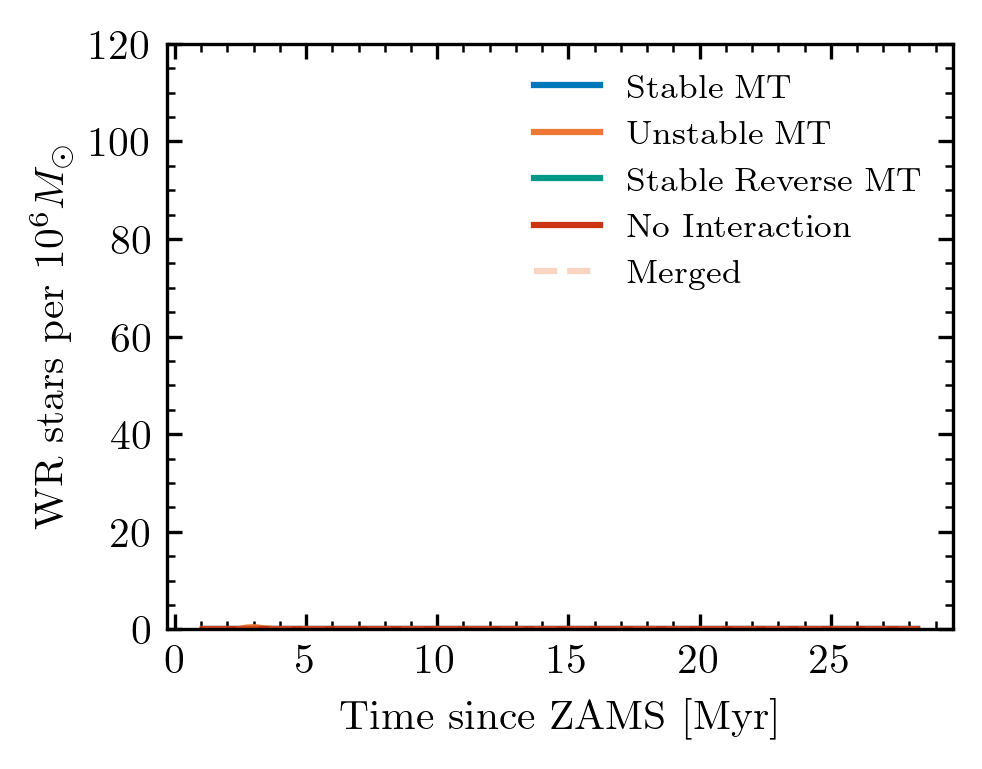

0.1
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


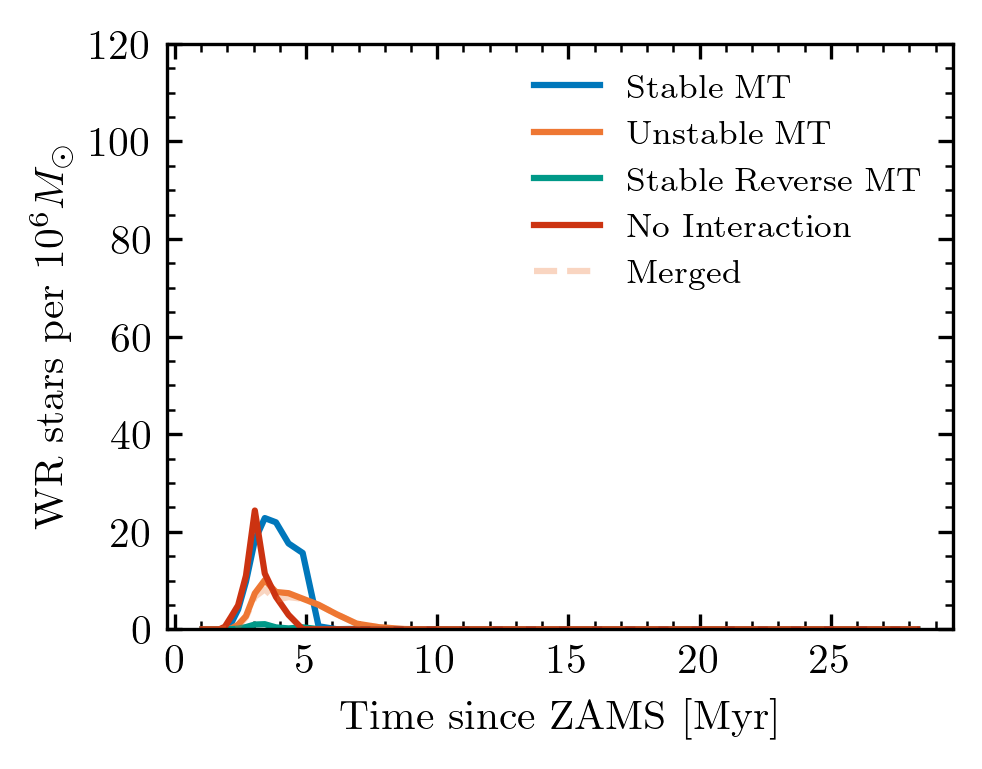

0.2
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


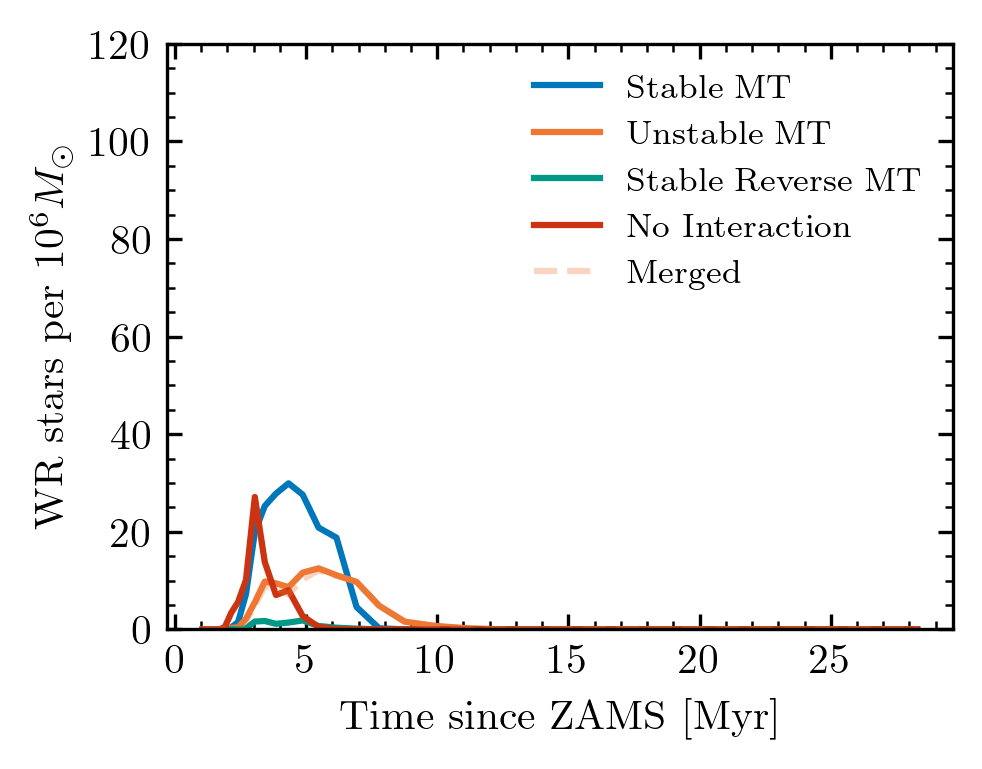

0.45
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


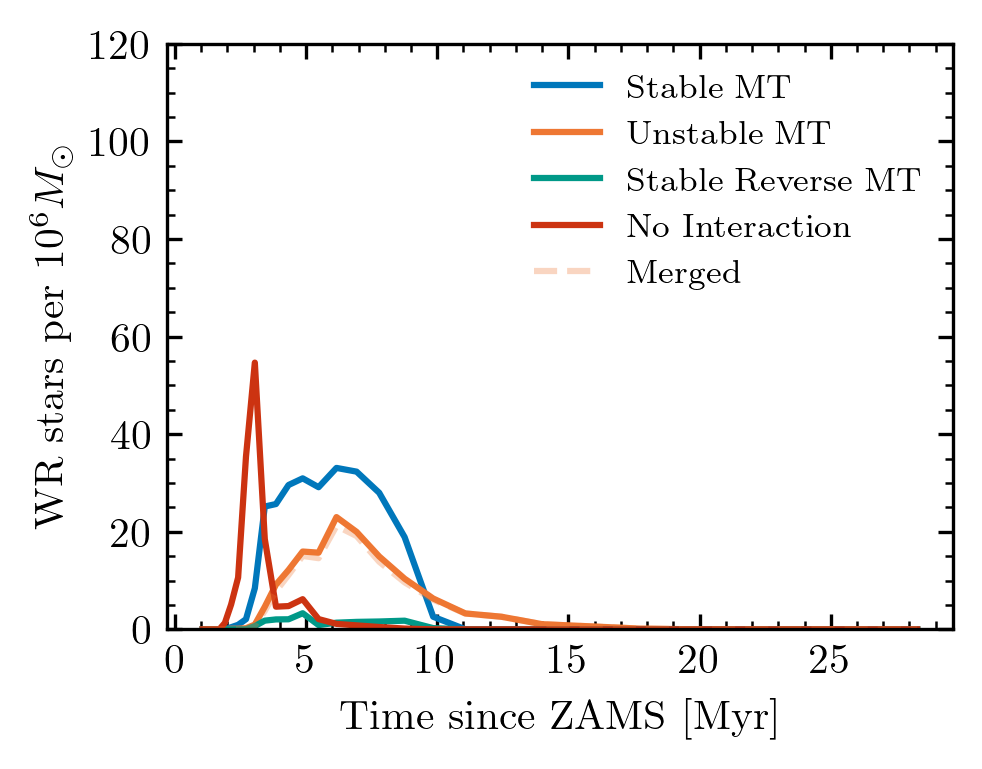

1.0
Missing ini parameter: metallicity
Missing ini parameter: metallicity


/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_44300/2914903879.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


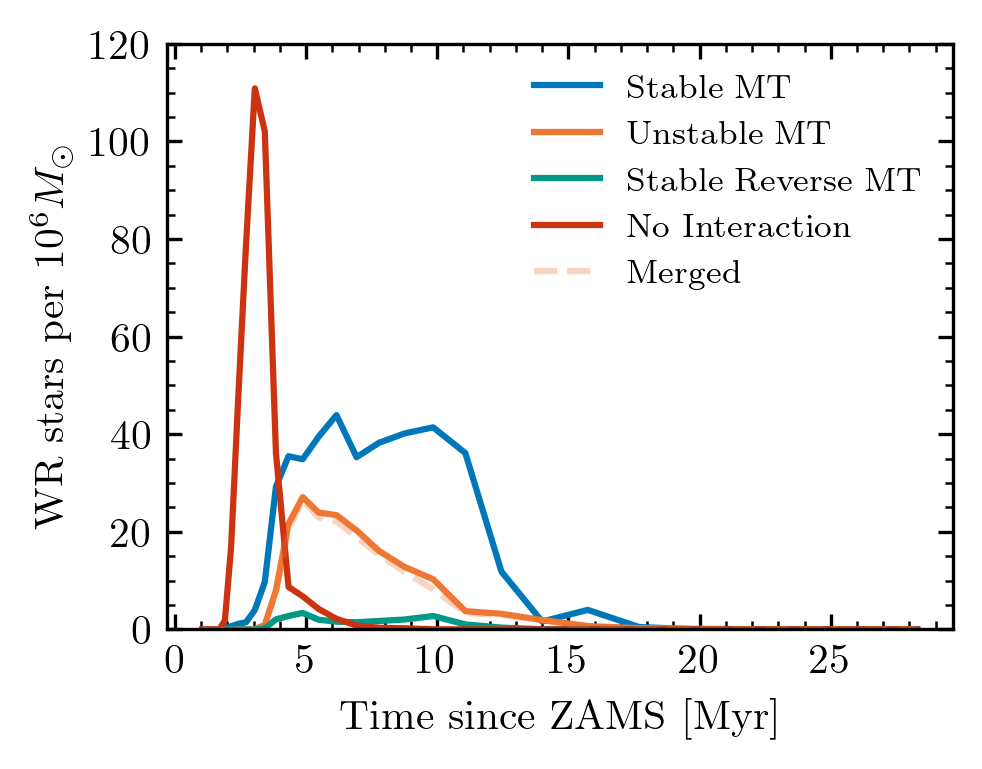

<Figure size 1014x760.5 with 0 Axes>

In [93]:
for metallicity in [0.01, 0.1, 0.2, 0.45, 1.0]:
    print(metallicity)
    met_str = convert_metallicity_to_string(metallicity)
    WR_data = pickle.load(open(f'WR_data_{met_str}_Zsun_shiftL.pkl', 'rb'))
    pop = Population(data_folder + f"{met_str}_Zsun_population.h5")
    WR_pop = TransientPopulation(data_folder + f"{met_str}_Zsun_population.h5", transient_name='WR_shiftL')
    weights = WR_pop.model_weights('standard')
    
    # shifting WR boundary in L
    
    # split per interaction type
    # stable, unstable, no interaction, NaN (no interaction too)
    oneline_data = WR_pop.oneline[list(WR_data.keys())]['interp_class_HMS_HMS']
    
    # stable
    stable_WR_data = {}
    # stable indices
    stable_indices = oneline_data[oneline_data == 'stable_MT'].index
    for i in stable_indices:
        stable_WR_data[i] = WR_data[i]
        
    unstable_indices = oneline_data[oneline_data == 'unstable_MT'].index
    unstable_WR_data = {}
    for i in unstable_indices:
        unstable_WR_data[i] = WR_data[i]
        
    stable_reverse_indices = oneline_data[oneline_data == 'stable_reverse_MT'].index
    stable_reverse_WR_data = {}
    for i in stable_reverse_indices:
        stable_reverse_WR_data[i] = WR_data[i]

    no_interaction_indices = oneline_data[pd.isna(oneline_data) | (oneline_data == 'no_MT')].index
    no_interaction_WR_data = {}
    for i in no_interaction_indices:
        no_interaction_WR_data[i] = WR_data[i]    
    
    data_array =  [stable_WR_data, unstable_WR_data, stable_reverse_WR_data, no_interaction_WR_data]
    label_array = ['Stable MT', 'Unstable MT', 'Stable Reverse MT', 'No Interaction']

    colour_array = ['#0077BB', '#EE7733', '#009988', '#CC3311']
    for data, label, colour in zip(data_array, label_array, colour_array):
        bin_weights, bin_centers = bin_wr_durations(data, time_bins, weights=weights)
        plt.plot(bin_centers/1e6, bin_weights*1e6, label=label, color=colour)

    # merged
    merged_WR_data = {}
    for key, value in WR_data.items():
        state = WR_data[key]['data']['state']
        mask = state == 'merged'
        if np.any(mask):
            merged_WR_data[key] = value

    merged_bin_weights, merged_bin_centers = bin_wr_durations(merged_WR_data, time_bins, weights=weights)
    
    plt.plot(merged_bin_centers/1e6, merged_bin_weights*1e6, color=colour_array[1], alpha=0.3, linestyle='--', label='Merged')

    plt.ylim(0, 120)
    plt.legend()
    plt.xlabel('Time since ZAMS [Myr]')
    plt.ylabel('WR stars per $10^6 M_\odot$')
    plt.show()
    plt.clf()


# Periods distribution

In [ ]:
for 




{8: {'duration': 38098.31294006854,
  'data':               S1_surface_h1          time     state event step_names  \
  binary_index                                                           
  8                  0.354956  1.736027e+07      RLO1   NaN        NaN   
  8                  0.354722  1.736029e+07      RLO1   NaN        NaN   
  8                  0.354414  1.736051e+07      RLO1   NaN        NaN   
  8                  0.354124  1.736080e+07  detached   NaN        NaN   
  8                  0.353987  1.736917e+07  detached   NaN        NaN   
  8                  0.353987  1.738119e+07  detached   NaN        NaN   
  8                  0.342571  1.739837e+07  detached   NaN        NaN   
  
                S1_log_L   S1_mass   S2_mass                S1_state  \
  binary_index                                                         
  8             4.901794  5.316452  7.319537  H-rich_Core_He_burning   
  8             4.913984  5.316434  7.320539  H-rich_Core_He_burning   

L = 4\pi R^2 * sigma * Teff^4

Teff = (L/(4pi R^2 *sigma))^(1/4)

In [ ]:
def Teff(L, R):
    '''Calculate effective temperature from luminosity and radius.
    
    Parameters:
    L : float
        Luminosity in solar luminosities (L_sun).
    R : float
        Radius in solar radii (R_sun).
    Returns:
    Teff : float
        Effective temperature in Kelvin (K).
    '''
    sigma = 5.67037442 * 10**-8 #kg s-3 K-4
    L = L * 3.828e26  # Convert L_sun to Watts
    R = R * 6.957e8   # Convert R_sun to meters
    return (L / (4 * np.pi * R**2 * sigma))**0.25
    

L_arr = []
R_arr = []
Teff_arr = []
for i in WR_data.items():
    L_arr.extend(i[1]['data']['S1_log_L'].to_list())
    R_arr.extend(i[1]['data']['S1_log_R'].to_list())
    Teff_arr.extend(Teff(10**i[1]['data']['S1_log_L'], 10**i[1]['data']['S1_log_R']).to_list())


In [ ]:
def bin_wr_2d(WR_data, x_bins, y_bins, x_key, y_key, weights=None):
    """
    Create a 2D histogram of WR systems weighted by time spent in each bin.
    
    Parameters:
    -----------
    WR_data : dict
        Dictionary with integer keys, each containing 'duration' and 'data' (DataFrame)
    x_bins : array-like
        Bin edges for x-axis (e.g., T_bins for temperature)
    y_bins : array-like
        Bin edges for y-axis (e.g., L_bins for luminosity)
    x_key : str or callable
        Column name in 'data' DataFrame for x-axis, or callable that takes 'data' and returns x values
    y_key : str
        Column name in 'data' DataFrame for y-axis
    weights : pd.Series or None
        Model weights for each system (indexed by WR_data keys). If None, uses 1.0 for all.
    
    Returns:
    --------
    hist_2d : np.array
        2D array of shape (len(y_bins)-1, len(x_bins)-1) with weighted counts
    x_centers : np.array
        Centers of x bins
    y_centers : np.array
        Centers of y bins
    """
    import numpy as np
    
    n_x_bins = len(x_bins) - 1
    n_y_bins = len(y_bins) - 1
    hist_2d = np.zeros((n_y_bins, n_x_bins))
    
    # Process each WR system
    for sys_id, wr_info in WR_data.items():
        data = wr_info['data']
        
        # Get system weight
        if weights is not None:
            sys_weight = weights.loc[sys_id]
        else:
            sys_weight = 1.0
        
        # Get x values (either from column or by calling function)
        if callable(x_key):
            x_values = x_key(data)
        else:
            x_values = data[x_key].values
        
        # Get y values
        y_values = data[y_key].values
        
        # Get time values
        times = data['time'].values
        
        # Calculate time spent in each row
        if len(times) == 1:
            # Single point - assign full duration to that bin
            durations = np.array([wr_info['duration']])
        else:
            # Calculate time differences between consecutive points
            time_diffs = np.diff(times)
            # Assign half of adjacent intervals to each point
            durations = np.zeros(len(times))
            durations[0] = time_diffs[0] / 2
            durations[-1] = time_diffs[-1] / 2
            for i in range(1, len(times) - 1):
                durations[i] = (time_diffs[i-1] + time_diffs[i]) / 2
        
        # Bin each point
        for x_val, y_val, duration in zip(x_values, y_values, durations):
            # Find which bin this point belongs to
            x_idx = np.searchsorted(x_bins[1:], x_val)
            y_idx = np.searchsorted(y_bins[1:], y_val)
            
            # Check if within bounds
            if 0 <= x_idx < n_x_bins and 0 <= y_idx < n_y_bins:
                hist_2d[y_idx, x_idx] += sys_weight * duration
    
    # Calculate bin centers
    x_centers = (x_bins[:-1] + x_bins[1:]) / 2
    y_centers = (y_bins[:-1] + y_bins[1:]) / 2
    
    return hist_2d, x_centers, y_centers


In [ ]:
def get_log_teff(data):
    """Calculate log10(Teff) from luminosity and radius"""
    sigma = 5.67037442e-8  # Stefan-Boltzmann constant
    L = 10**data['S1_log_L'].values * 3.828e26  # L_sun to Watts
    R = 10**data['S1_log_R'].values * 6.957e8   # R_sun to meters
    Teff = (L / (4 * np.pi * R**2 * sigma))**0.25
    return np.log10(Teff)

In [ ]:
T_bins = np.linspace(3.2, 5.5, 100)
L_bins = np.linspace(4.9, 6.0, 100)

hist_2d, T_centers, L_centers = bin_wr_2d(
    WR_data, 
    T_bins, 
    L_bins, 
    x_key=get_log_teff,  # Function to calculate log10(Teff)
    y_key='S1_log_L',    # Column name for luminosity
    weights=weights       # Model weights from POSYDON
)

/var/folders/81/1prqtbls4czbn2cc9672cgxh0000gn/T/ipykernel_43142/4290195229.py:79: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


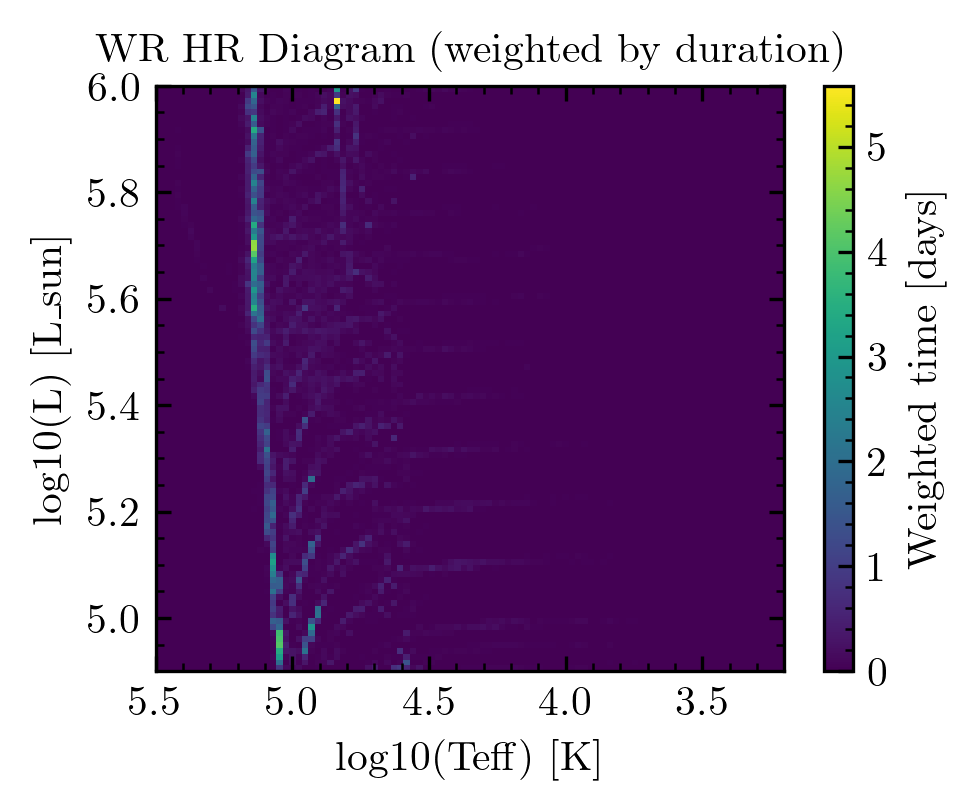

In [ ]:
fig, ax = plt.subplots()
im = ax.pcolormesh(T_bins, L_bins, hist_2d, shading='auto', cmap='viridis')
ax.set_xlabel('log10(Teff) [K]')
ax.set_ylabel('log10(L) [L_sun]')
ax.set_xlim(T_bins[-1], T_bins[0])
ax.set_title('WR HR Diagram (weighted by duration)')
plt.colorbar(im, ax=ax, label='Weighted time [days]')
plt.show()

In [ ]:
WR_data.keys()

dict_keys([8, 15, 22, 24, 25, 27, 28, 34, 36, 37, 38, 41, 43, 52, 55, 57, 69, 76, 81, 82, 89, 92, 100, 109, 111, 114, 115, 116, 118, 120, 122, 123, 124, 126, 127, 128, 132, 134, 136, 146, 149, 152, 153, 154, 156, 157, 159, 160, 162, 166, 167, 169, 171, 175, 177, 181, 183, 190, 194, 198, 199, 215, 216, 220, 222, 224, 227, 229, 231, 232, 235, 238, 240, 241, 242, 244, 247, 248, 251, 268, 274, 279, 282, 284, 286, 295, 297, 298, 304, 305, 315, 317, 324, 327, 328, 331, 333, 337, 341, 342, 343, 349, 352, 355, 356, 376, 380, 383, 384, 388, 389, 390, 393, 394, 396, 399, 401, 404, 408, 414, 417, 427, 432, 434, 439, 442, 445, 446, 448, 456, 457, 458, 464, 470, 473, 475, 481, 484, 486, 489, 490, 491, 493, 495, 498, 507, 508, 512, 514, 519, 521, 526, 527, 530, 531, 532, 545, 546, 548, 551, 553, 558, 559, 568, 570, 576, 590, 594, 602, 605, 606, 607, 614, 616, 628, 629, 630, 631, 636, 637, 650, 659, 660, 664, 668, 674, 684, 691, 692, 696, 699, 703, 705, 708, 718, 721, 725, 729, 731, 734, 738, 741, 74

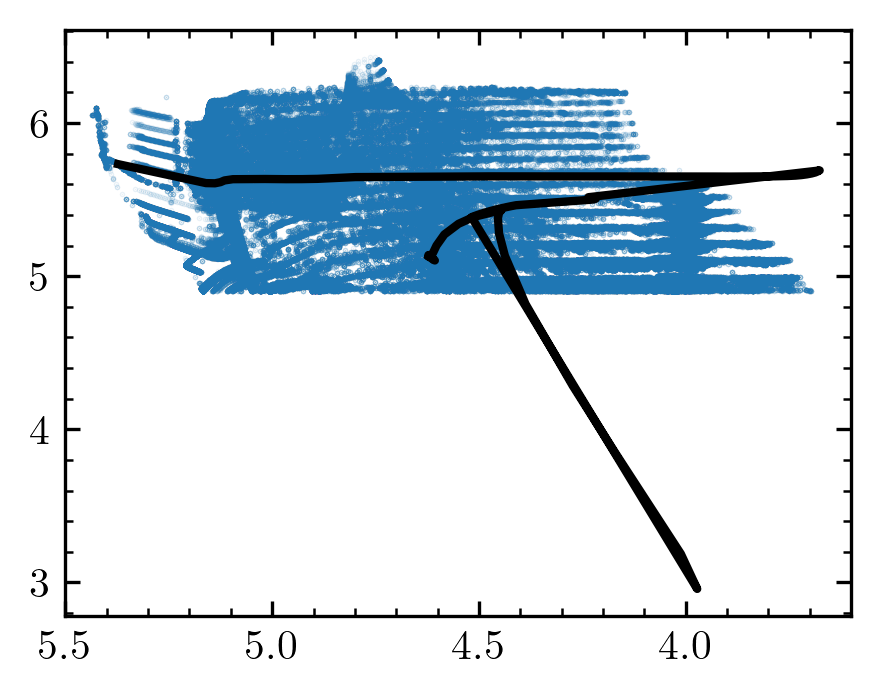

In [ ]:
plt.scatter(np.log10(Teff_arr), L_arr, s=0.1, alpha=0.1)
plt.xlim(5.5, 3.6)
example_index = 636

Teff_example = Teff(10**pop.history[example_index]['S1_log_L'], 10**pop.history[example_index]['S1_log_R'])
plt.plot(np.log10(Teff_example), pop.history[example_index]['S1_log_L'], color='black', lw=2)

In [ ]:
pop.history[example_index]

,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
636,detached,ZAMS,0.000000e+00,4.463074e+00,0.0,NaN,initial_cond,0.000000,H-rich_Core_H_burning,29.997252,...,0.0,NaN,NaN,NaN,0.715500,0.270300,NaN,NaN,NaN,NaN
636,detached,NaN,1.779122e+01,5.179476e+00,0.0,-99.0,step_HMS_HMS,0.008481,H-rich_Core_H_burning,31.616780,...,0.0,0.0,0.0,0.0,0.714006,0.271409,0.7155,0.270271,0.044258,1.269131
636,detached,NaN,1.779122e+01,5.179476e+00,0.0,-99.0,NaN,NaN,H-rich_Core_H_burning,31.616780,...,0.0,0.0,0.0,0.0,0.714006,0.271409,0.7155,0.270271,0.044258,1.269131
636,detached,NaN,2.935389e+02,5.179495e+00,0.0,-99.0,NaN,NaN,H-rich_Core_H_burning,31.616708,...,0.0,0.0,0.0,0.0,0.714219,0.271205,0.7155,0.270271,0.044221,1.269131
636,detached,NaN,7.041855e+02,5.179519e+00,0.0,-99.0,NaN,NaN,H-rich_Core_H_burning,31.616608,...,0.0,0.0,0.0,0.0,0.714346,0.271094,0.7155,0.270271,0.043995,1.269131
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
636,merged,NaN,7.127557e+06,1.415313e+99,0.0,NaN,NaN,NaN,stripped_He_Core_He_burning,14.671316,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
636,merged,NaN,7.144942e+06,1.432036e+99,0.0,NaN,NaN,NaN,stripped_He_non_burning,14.330666,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
636,merged,CC1,7.162327e+06,NaN,NaN,NaN,NaN,NaN,stripped_He_Core_C_depleted,13.972636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
tmp_data = pop.oneline[['interp_class_HMS_HMS', 'interp_class_CO_HMS_RLO', 'mt_history_HMS_HMS', 'mt_history_CO_HMS_RLO']]

In [ ]:
value_counts = tmp_data['interp_class_HMS_HMS'].value_counts()

unstable_mt_count = value_counts['unstable_MT'] 
stable_mt_count = value_counts['stable_MT']
no_mt_count = value_counts['no_MT']
stable_reverse_mt_count = value_counts['stable_reverse_MT']

interacting_count = unstable_mt_count + stable_mt_count + stable_reverse_mt_count

interacting_fraction = interacting_count / tmp_data.shape[0]

print(f"Total systems: {tmp_data.shape[0]}"
      f"\nInteracting systems: {interacting_count}"
      f"\nInteracting fraction: {interacting_fraction*100:.2f}%")


Total systems: 100000
Interacting systems: 87669
Interacting fraction: 87.67%


In [ ]:
WR_data = {}

for i in range(100000):
    example = tmp_hist.loc[i]
    surface_threshold = 0.4
    luminosity_threshold = 4.9
    
    mask = example['S1_surface_h1'] < surface_threshold
    mask2 = example['event'] != 'CC1'
    stripped_phase = example[mask & mask2]
    
    # Check if stripped_phase is empty
    if len(stripped_phase) == 0:
        continue
    
    mask_L = stripped_phase['S1_log_L'] >= luminosity_threshold
    stripped_phase = stripped_phase[mask_L]
    
    # Check again if stripped_phase is empty after applying luminosity threshold
    if len(stripped_phase) == 0:
        continue
        
    duration = stripped_phase['time'].iloc[-1] - stripped_phase['time'].iloc[0]
    start_time = stripped_phase['time'].iloc[0]
    end_time = stripped_phase['time'].iloc[-1]

    #stripped_phase
    WR_data[i] = {'duration': duration,
                  'data': stripped_phase}
    
    

In [ ]:
time_bins = np.logspace(np.log10(1e6), np.log10(3e7), 14)

def bin_wr_durations(WR_data, time_bins, weights=None):
    # Initialize weights array
    n_bins = len(time_bins) - 1
    bin_weights = np.zeros(n_bins)
    
    # Default weights to 1.0 if not provided
    if weights is None:
        weights = {key: 1.0 for key in WR_data.keys()}
    
    # Process each WR system
    for sys_id, wr_info in WR_data.items():
        # Get start and end times
        start_time = wr_info['data']['time'].iloc[0]
        end_time = wr_info['data']['time'].iloc[-1]
        total_duration = end_time - start_time
        
        # Get weight for this system
        sys_weight = weights.get(sys_id, 1.0)
        
        # Skip if duration is zero
        if total_duration == 0:
            continue
        
        # Find which bins this WR phase overlaps with
        for i in range(n_bins):
            bin_start = time_bins[i]
            bin_end = time_bins[i + 1]
            
            # Calculate overlap between WR phase and this bin
            overlap_start = max(start_time, bin_start)
            overlap_end = min(end_time, bin_end)
            
            # If there's overlap, add proportional weight
            if overlap_start < overlap_end:
                overlap_duration = overlap_end - overlap_start
                fraction = overlap_duration / total_duration
                bin_weights[i] += sys_weight * fraction
    
    # Calculate bin centers (geometric mean for log-spaced bins)
    bin_centers = np.sqrt(time_bins[:-1] * time_bins[1:])
    
    return bin_weights, bin_centers

In [ ]:
# load a Psygrid 

In [ ]:
bin_weights, bin_centers = bin_wr_durations(WR_data, time_bins)

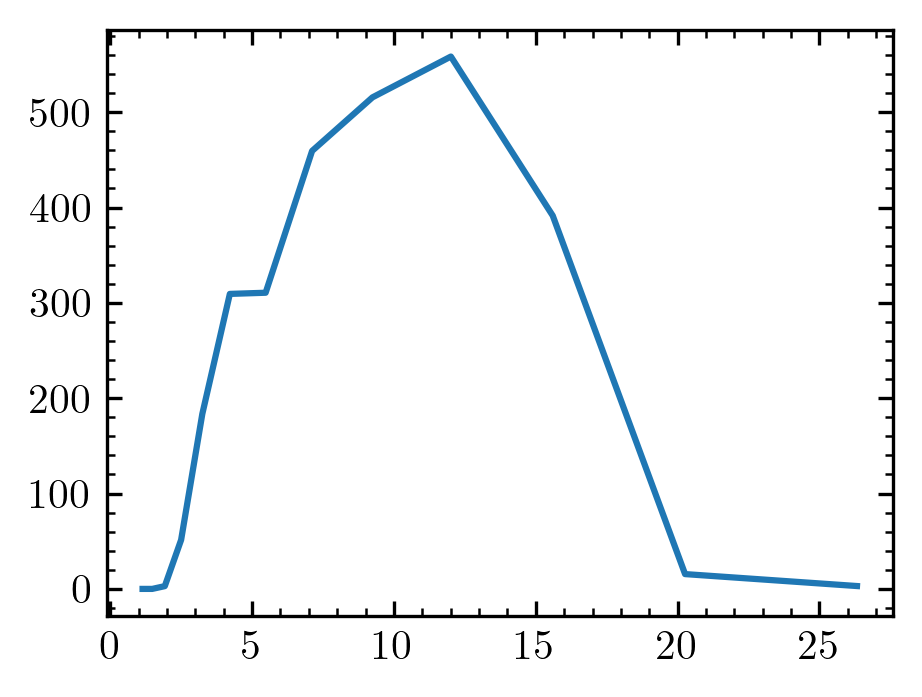

In [ ]:
import matplotlib.pyplot as plt
plt.plot(bin_centers/1e6, bin_weights)

In [ ]:
value_counts = tmp_data['interp_class_HMS_HMS'].value_counts()

unstable_mt_count = value_counts.get('unstable_MT', 0)
stable_mt_count = value_counts.get('stable_MT', 0)
no_mt_count = value_counts.get('no_MT', 0)
stable_reverse_mt_count = value_counts.get('stable_reverse_MT', 0)

total_systems = tmp_data.shape[0]

# Define nodes
# Node 0: All Systems (left)
# Node 1: Unstable MT (right, top)
# Node 2: Stable MT (right, middle-top)
# Node 3: Stable Reverse MT (right, middle-bottom)
# Node 4: No MT (bottom)

node_labels = [
    f"All Systems<br>({total_systems:,})",
    f"No MT<br>({no_mt_count:,})",
    f"Interacting Systems<br>({unstable_mt_count + stable_mt_count + stable_reverse_mt_count:,})",
    f"Stable MT<br>({stable_mt_count:,})",
    f"Unstable MT<br>({unstable_mt_count:,})",
    f"Stable Reverse MT<br>({stable_reverse_mt_count:,})",
    
]

# Define links
source = [0, 0, 2, 2, 2]  
target = [1, 2, 3, 4, 5] 
value = [no_mt_count, 
         stable_mt_count+unstable_mt_count+stable_reverse_mt_count,
         stable_mt_count,
         unstable_mt_count,
         stable_reverse_mt_count]
#value = [unstable_mt_count, stable_mt_count, stable_reverse_mt_count, no_mt_count]

# Custom node positions
# x: 0 for left (all systems), 1 for right (interacting types) and bottom (no MT)
# y: vertical position
node_x = [0.1, 0.3, 0.3, 0.7, 0.7, 0.7]
node_y = [0.5, 0.92, 0.45, 0.1, 0.52, 0.75]


fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=node_labels,
        x=node_x,
        y=node_y
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
    )
)])

fig.update_layout(
    title=f"Binary System Interactions (Z = {metallicity}"+r"$Z_\odot$)",
    font=dict(size=12),
    height=600,
    width=900
)

fig.show()

## across metallicity

In [ ]:
from posydon.utils.common_functions import convert_metallicity_to_string
import numpy as np
import pandas as pd

metallicities = [0.01, 0.1, 0.2, 0.45, 1.0]
for met in metallicities:
    data_folder = '/home/users/b/briel/scratch/WR_populations/population_synthesis/runs/2025_11_04/'
    metallicity = met  # in units of Z_sun
    print(f"Metallicity: {metallicity} Z_sun")
    met_str = convert_metallicity_to_string(metallicity)

    metallicity_file = data_folder + f"{met_str}_Zsun_population.h5"

    pop = Population(metallicity_file)

    tmp_data = pop.oneline[['interp_class_HMS_HMS', 'interp_class_CO_HMS_RLO', 'mt_history_HMS_HMS', 'mt_history_CO_HMS_RLO']]
    value_counts = tmp_data['interp_class_HMS_HMS'].value_counts()

    unstable_mt_count = value_counts['unstable_MT'] 
    stable_mt_count = value_counts['stable_MT']
    no_mt_count = value_counts['no_MT']
    stable_reverse_mt_count = value_counts['stable_reverse_MT']

    interacting_count = unstable_mt_count + stable_mt_count + stable_reverse_mt_count

    interacting_fraction = interacting_count / tmp_data.shape[0]

    print(f"Total systems: {tmp_data.shape[0]}"
        f"\nInteracting systems: {interacting_count}"
        f"\nInteracting fraction: {interacting_fraction*100:.2f}%"
        f"\nStable MT: {stable_mt_count} ({(stable_mt_count/tmp_data.shape[0])*100:.2f}%)"
        f"\nUnstable MT: {unstable_mt_count} ({(unstable_mt_count/tmp_data.shape[0])*100:.2f}%)"
        f"\nStable Reverse MT: {stable_reverse_mt_count} ({(stable_reverse_mt_count/tmp_data.shape[0])*100:.2f}%)"
    )


Metallicity: 0.01 Z_sun
Total systems: 100000
Interacting systems: 89157
Interacting fraction: 89.16%
Stable MT: 45718 (45.72%)
Unstable MT: 42406 (42.41%)
Stable Reverse MT: 1033 (1.03%)
Metallicity: 0.1 Z_sun
Total systems: 100000
Interacting systems: 89391
Interacting fraction: 89.39%
Stable MT: 41792 (41.79%)
Unstable MT: 46564 (46.56%)
Stable Reverse MT: 1035 (1.03%)
Metallicity: 0.2 Z_sun
Total systems: 100000
Interacting systems: 89794
Interacting fraction: 89.79%
Stable MT: 42082 (42.08%)
Unstable MT: 46537 (46.54%)
Stable Reverse MT: 1175 (1.18%)
Metallicity: 0.45 Z_sun
Total systems: 100000
Interacting systems: 89240
Interacting fraction: 89.24%
Stable MT: 41315 (41.32%)
Unstable MT: 46727 (46.73%)
Stable Reverse MT: 1198 (1.20%)
Metallicity: 1.0 Z_sun
Total systems: 100000
Interacting systems: 87669
Interacting fraction: 87.67%
Stable MT: 41444 (41.44%)
Unstable MT: 45168 (45.17%)
Stable Reverse MT: 1057 (1.06%)


Looking at just the first interaction, the following conclusions can be drawn:


1. For the total interacting systems, there's only a small change in the % of interacting systems. Only at 1\Zsun is there a jump down in interacting systems. Most likely from strong winds stopping intactions.
2. The percentage of stable and unstbale systems remains 